<a href="https://colab.research.google.com/github/Silyaemna/ml/blob/main/main_fedcgs_py%2B%2B__new.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/Yuqin-G/FedCGS.git

Cloning into 'FedCGS'...
remote: Enumerating objects: 208, done.
remote: Counting objects: 100% (208/208), done.
remote: Compressing objects: 100% (182/182), done.
remote: Total 208 (delta 65), reused 159 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (208/208), 204.35 KiB | 1.95 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [ ]:
%cd FedCGS

/content/FedCGS


In [ ]:
!pip install -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 36.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
!pip install torch torchvision torchaudio

In [ ]:
!pip install --upgrade sympy networkx

In [ ]:
import torch
import math
import numpy as np
import registry
import torch
import logging
from utils_fl import partition_data, DataLoader, DatasetSplit, get_dataset, eval, get_model
from PIL import Image
from torch.nn import functional as F
from tqdm import tqdm


def logger_config(log_path, logging_name):
    logger = logging.getLogger(logging_name)
    logger.setLevel(level=logging.DEBUG)
    handler = logging.FileHandler(log_path, mode='w',encoding='UTF-8')
    handler.setLevel(level=logging.DEBUG)
    formatter = logging.Formatter('%(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)
    return logger

import argparse

if __name__ == "__main__":
    args = argparse.Namespace()
    logger = logger_config(log_path='./test.log', logging_name='test')
    device = torch.device('cuda:4')
    dataset_list = ["cifar100", "cifar10", "svhn"]
    beta_list = [0.05, 0.1, 0.3, 0.5]
    for dataset in dataset_list:
        print(dataset)
        args.dataset = dataset
        for beta in beta_list:
            print(beta)
            num_classes, train_dataset, test_dataset = get_dataset(name=args.dataset, data_root='/home/guanzenghao/data/')
            print(len(train_dataset))
            train_dataset, test_dataset, user_groups, traindata_cls_counts = partition_data(
                train_dataset, test_dataset, 'dir', beta=beta, num_users=100, logger=logger, args=args)

            test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256,
                                                            shuffle=False, num_workers=4)
            user_num = [len(user_groups[i]) for i in range(len(user_groups))]
            num_users = len(user_groups)

            train_loader_list = [DataLoader(DatasetSplit(train_dataset, user_groups[i]), batch_size=1024, shuffle=False) for i in range(num_users)]
            train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False)

            model_name = "resnet18_imagenet"
            model, num_d = get_model(model_name, num_classes)

            device = 'cuda' if torch.cuda.is_available() else 'cpu'
            model.to(device)

            model.eval()

            cs_l = []
            cc_l = []
            Ax_l = []
            Bx_l = []
            #Feature Extraction and Client-Side Statistics Accumulation
            for i in range(len(train_loader_list)):
                cs1 = torch.zeros((num_classes, num_d)).double()
                cc1 = torch.zeros(num_classes)
                Ax1 = torch.zeros((num_d)).double()
                Bx1 = torch.zeros((num_d, num_d)).double()

                model = model.to(device)
                for i, (X, y) in enumerate(train_loader_list[i]):
                    with torch.no_grad():
                        X = X.to(device)
                        _, feature_t = model(X, return_features=True)
                        feature_t = feature_t.double()
                        feature_t = feature_t.cpu()
                        cs1.scatter_add_(0, y.unsqueeze(1).expand_as(feature_t).to(torch.int64), feature_t)
                        cc1.scatter_add_(0, y.to(torch.int64), torch.ones(len(y)))
                        Ax1 += feature_t.double().sum(axis=0)
                        Bx1 += feature_t.T @ feature_t
                    del feature_t, y, X
                cs_l.append(cs1)
                cc_l.append(cc1)
                Ax_l.append(Ax1)
                Bx_l.append(Bx1)

            cc = sum(cc_l)
            cs = sum(cs_l)
            Ax = sum(Ax_l)
            Bx = sum(Bx_l)

            N = cc.sum()
            mu = Ax / N

            mu_A = torch.ger(mu.T, Ax.double())
            A_mu = torch.ger(Ax.double().T, mu)
            mu_mu = torch.ger(mu.T, mu.double()) * N

            Sx = (Bx - mu_A - A_mu + mu_mu) / (N - 1)

            class_means = torch.div(cs, torch.reshape(cc, (-1, 1))).double()
            A, B, Aj, mu, S, N, Nj = Ax, Bx, class_means, mu, Sx, N, cc

            gamma_list = [0]
            for gamma in gamma_list:
                S_hat = S + gamma * torch.eye(num_d)
                S_inv = np.linalg.inv(S_hat.detach())
                S_inv = torch.tensor(S_inv)
                eval(model, Aj, S_inv, N, Nj, test_loader, device)





cifar100
0.05


  0%|          | 623k/169M [00:25<1:52:41, 24.9kB/s]


KeyboardInterrupt: 

In [ ]:
### Version ETF et visualization layer 3 sans noise

In [ ]:
#Calculating Neural Collapse (ETF) Metric...
#--> [GLOBAL] ETF Deviation Layer 3 (Before-Last): 13.4392  (LOWER = Better separation)
#--> [GLOBAL] ETF Deviation Layer 4 (Last Layer):  18.0058
    #CONCLUSION: Layer 3 is much more informative (better geometric collapse by 4.5666).

#Generating Neural Collapse ETF Heatmaps...
#Saved ETF Heatmaps to 'neural_collapse_etf_heatmap_cifar10_beta0.05.png'!
#--> Test Accuracy with Before-Last Layer Prototypes: 67.84%
#--> Test Accuracy with Last Layer Prototypes:        63.94%

In [ ]:
#Version 2: ETF avec noise avec visualization

In [ ]:
#+ figures and layer3

Using device: cuda

📁 Visualizations will be saved to: ./visualization_resultss
💡 4 figures per dataset: ETF deviation, Prototype distances, ETF comparison, Accuracy curves


📊 DATASET: CIFAR10

Beta: 0.05
----------------------------------------


INFO:test:Client ID   0: {np.int64(0): np.int64(30), np.int64(5): np.int64(1112), np.int64(9): np.int64(1)}
INFO:test:Client ID   1: {np.int64(0): np.int64(609), np.int64(5): np.int64(3746)}
INFO:test:Client ID   2: {np.int64(2): np.int64(719), np.int64(6): np.int64(345), np.int64(7): np.int64(13), np.int64(9): np.int64(684)}
INFO:test:Client ID   3: {np.int64(1): np.int64(421), np.int64(8): np.int64(3), np.int64(9): np.int64(2123)}
INFO:test:Client ID   4: {np.int64(3): np.int64(7), np.int64(7): np.int64(32)}
INFO:test:Client ID   5: {np.int64(6): np.int64(1889), np.int64(8): np.int64(396)}
INFO:test:Client ID   6: {np.int64(0): np.int64(39), np.int64(2): np.int64(1), np.int64(3): np.int64(2661)}
INFO:test:Client ID   7: {np.int64(4): np.int64(4970)}
INFO:test:Client ID   8: {np.int64(7): np.int64(2026), np.int64(8): np.int64(1)}
INFO:test:Client ID   9: {np.int64(1): np.int64(515), np.int64(6): np.int64(2663)}
INFO:test:Client ID  10: {np.int64(3): np.int64(3), np.int64(6): np.int64(


📊 FIGURE 1: ETF Deviation Curves (β=0.05)...


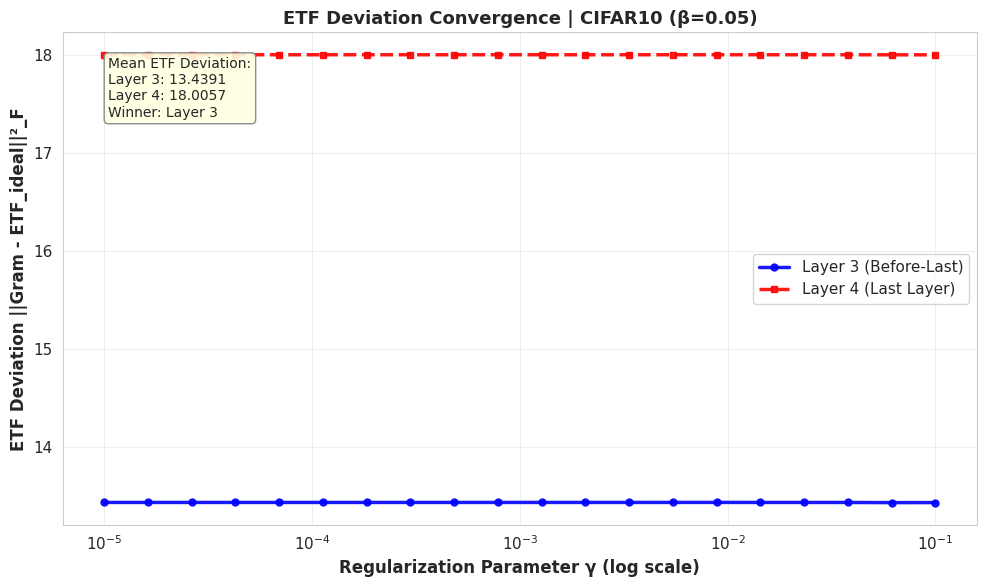


📊 FIGURE 2: Prototype Distance Analysis (β=0.05)...


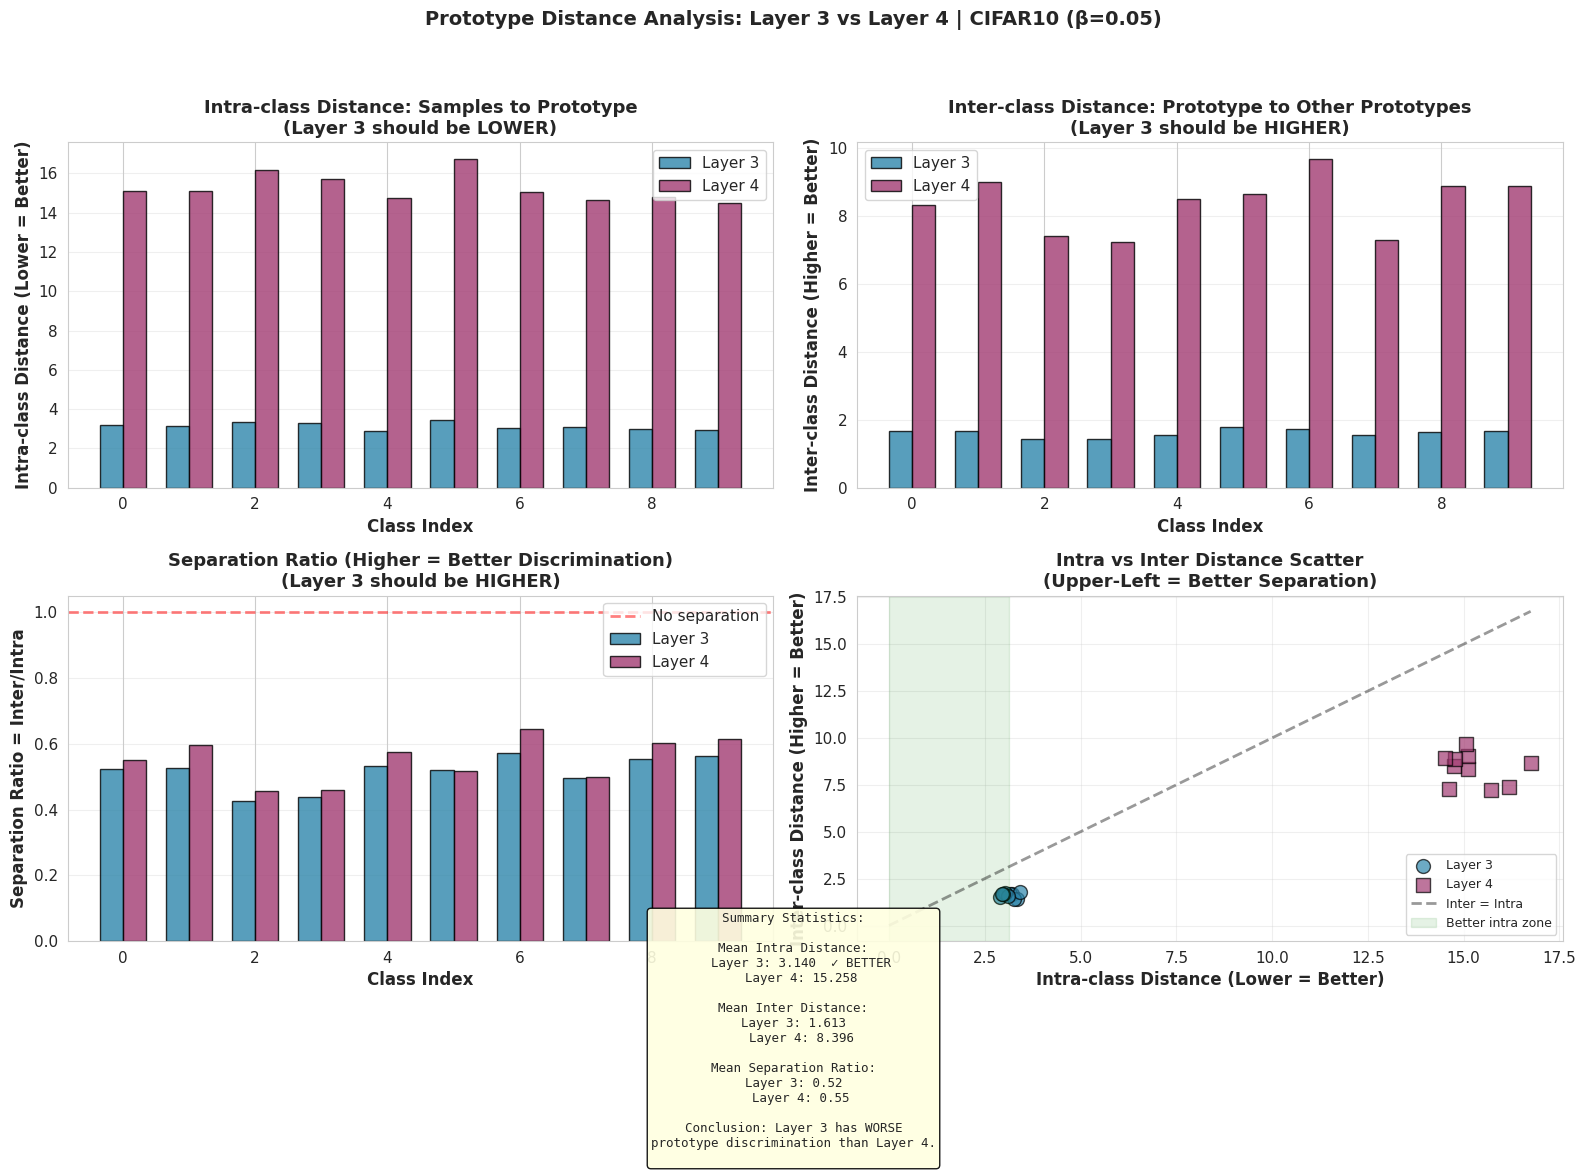


Beta: 0.1
----------------------------------------


INFO:test:Client ID   0: {np.int64(0): np.int64(173), np.int64(1): np.int64(66), np.int64(2): np.int64(4), np.int64(7): np.int64(24), np.int64(8): np.int64(43), np.int64(9): np.int64(4607)}
INFO:test:Client ID   1: {np.int64(0): np.int64(973), np.int64(2): np.int64(275), np.int64(3): np.int64(887), np.int64(4): np.int64(2), np.int64(6): np.int64(444)}
INFO:test:Client ID   2: {np.int64(0): np.int64(325), np.int64(2): np.int64(515), np.int64(4): np.int64(124), np.int64(5): np.int64(289), np.int64(8): np.int64(1145), np.int64(9): np.int64(16)}
INFO:test:Client ID   3: {np.int64(0): np.int64(2205), np.int64(1): np.int64(108), np.int64(2): np.int64(1), np.int64(3): np.int64(1), np.int64(4): np.int64(2176)}
INFO:test:Client ID   4: {np.int64(1): np.int64(3103)}
INFO:test:Client ID   5: {np.int64(0): np.int64(193), np.int64(1): np.int64(175), np.int64(2): np.int64(1), np.int64(4): np.int64(140), np.int64(6): np.int64(248), np.int64(8): np.int64(1), np.int64(9): np.int64(152)}
INFO:test:Clien


📊 FIGURE 1: ETF Deviation Curves (β=0.1)...


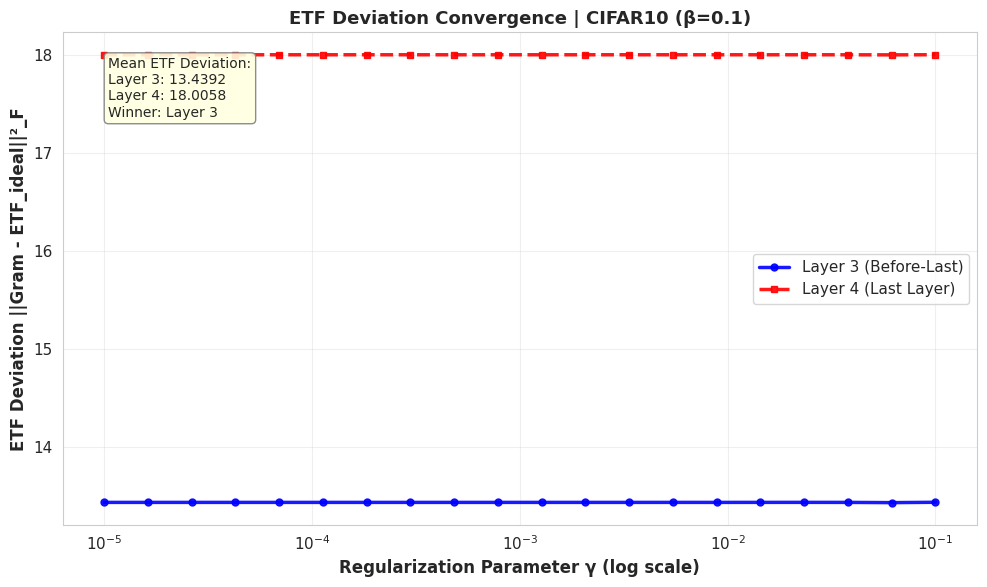


📊 FIGURE 2: Prototype Distance Analysis (β=0.1)...


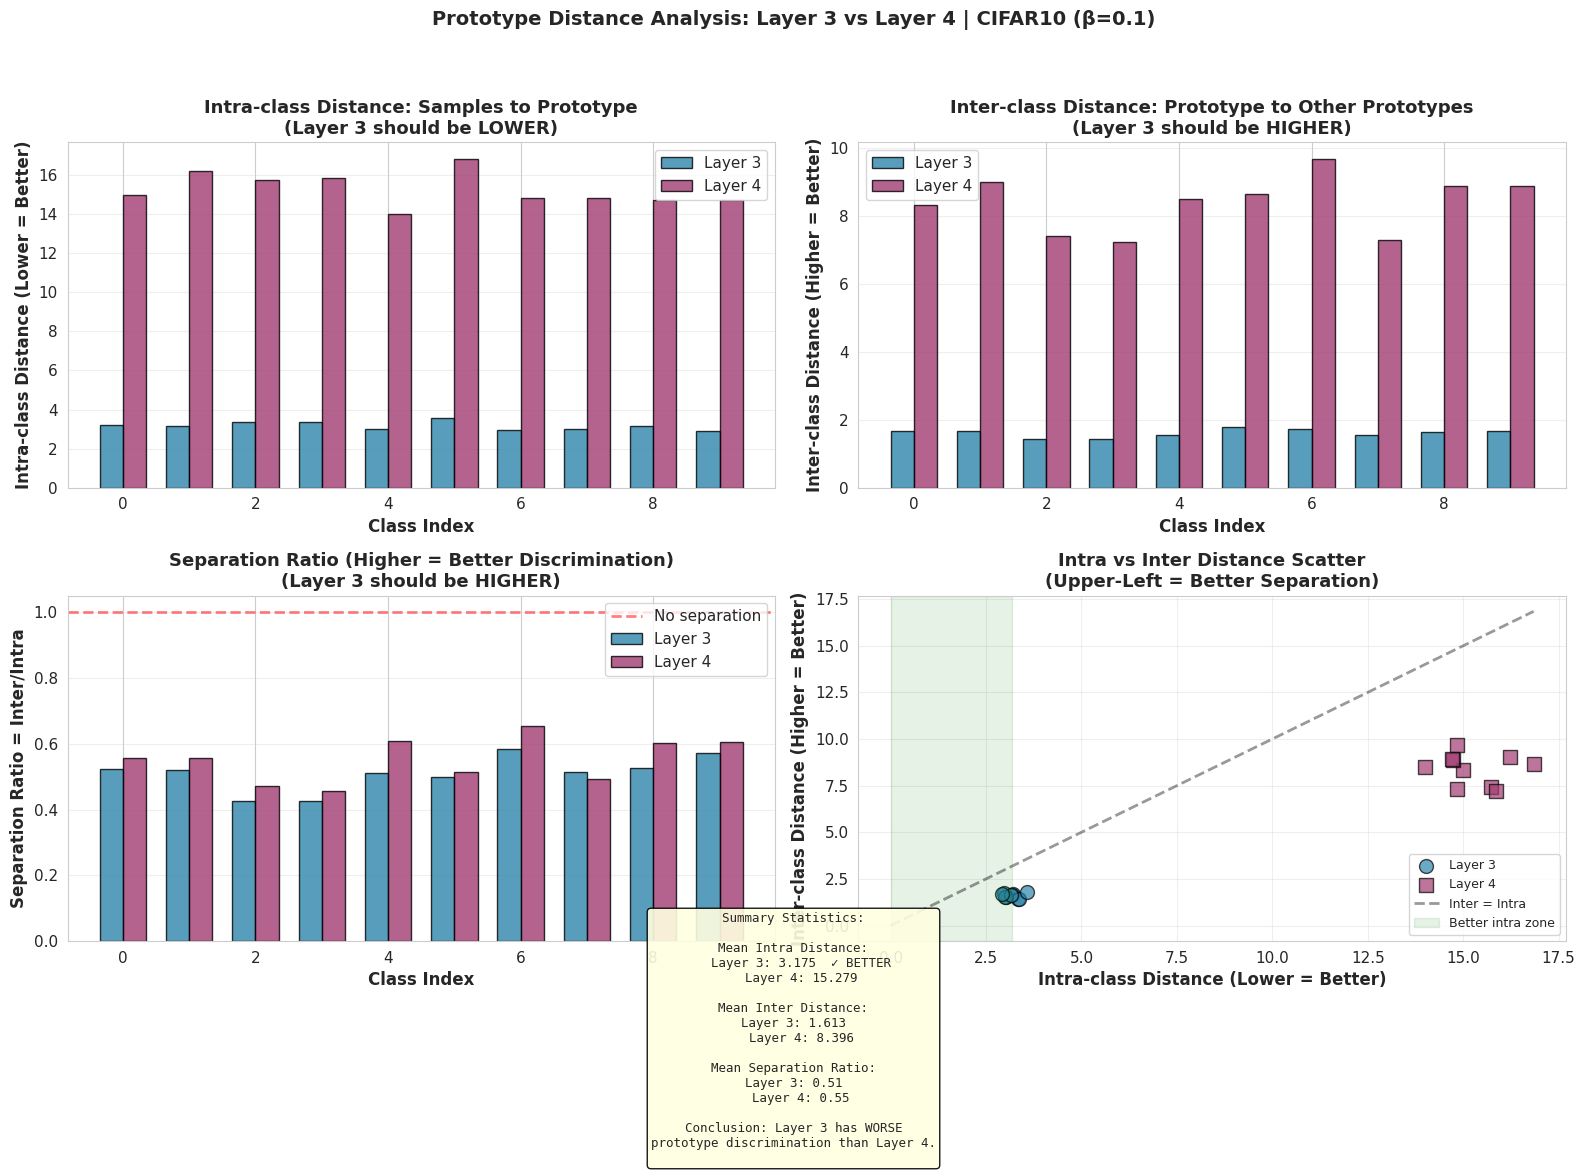


Beta: 0.5
----------------------------------------


INFO:test:Client ID   0: {np.int64(0): np.int64(36), np.int64(1): np.int64(909), np.int64(2): np.int64(666), np.int64(3): np.int64(26), np.int64(4): np.int64(431), np.int64(5): np.int64(255), np.int64(6): np.int64(95), np.int64(7): np.int64(483)}
INFO:test:Client ID   1: {np.int64(0): np.int64(13), np.int64(1): np.int64(84), np.int64(2): np.int64(4), np.int64(3): np.int64(42), np.int64(4): np.int64(569), np.int64(5): np.int64(319), np.int64(6): np.int64(138), np.int64(7): np.int64(45), np.int64(8): np.int64(358), np.int64(9): np.int64(1740)}
INFO:test:Client ID   2: {np.int64(0): np.int64(187), np.int64(1): np.int64(80), np.int64(2): np.int64(11), np.int64(3): np.int64(41), np.int64(4): np.int64(6), np.int64(5): np.int64(11), np.int64(6): np.int64(329), np.int64(7): np.int64(818), np.int64(8): np.int64(47), np.int64(9): np.int64(53)}
INFO:test:Client ID   3: {np.int64(0): np.int64(307), np.int64(1): np.int64(570), np.int64(2): np.int64(479), np.int64(3): np.int64(901), np.int64(4): np.


📊 FIGURE 1: ETF Deviation Curves (β=0.5)...


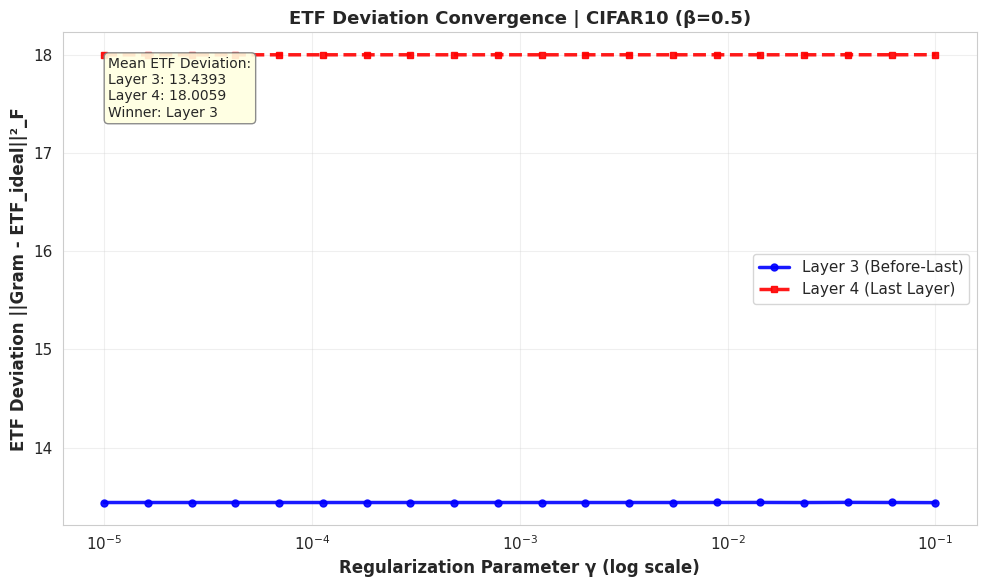


📊 FIGURE 2: Prototype Distance Analysis (β=0.5)...


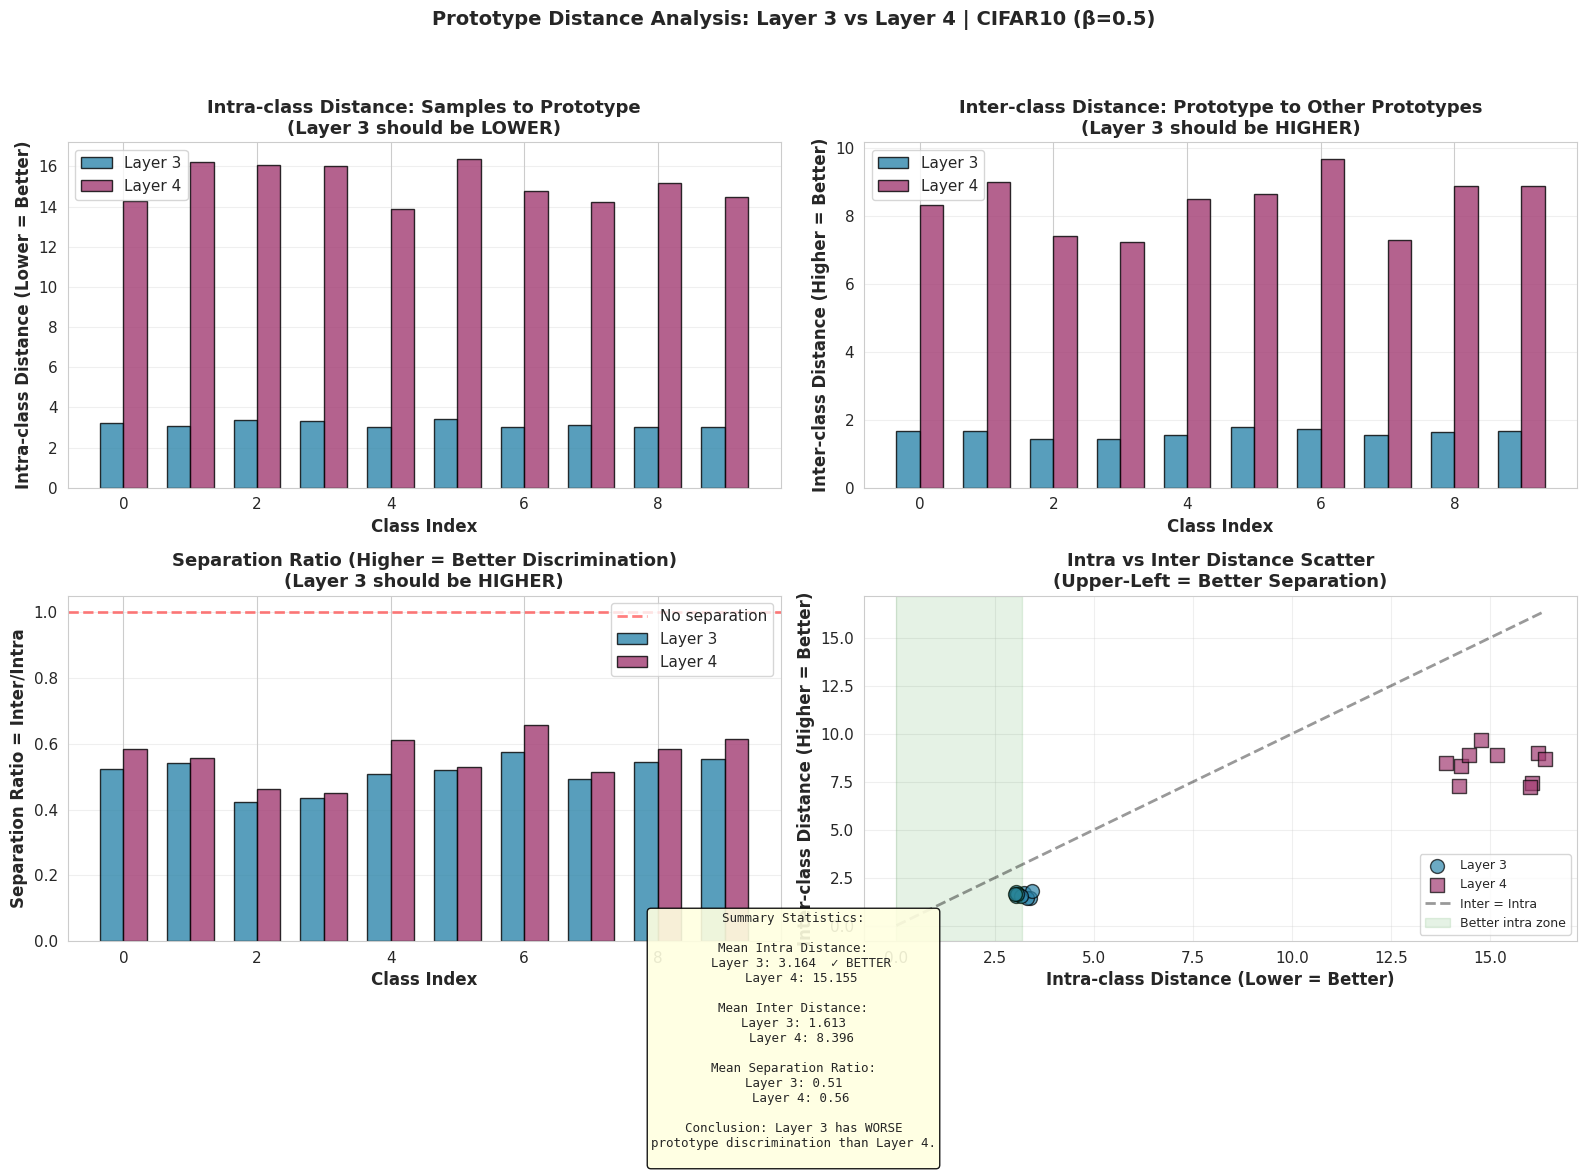


📊 FIGURE 3: ETF Comparison Bar Chart for CIFAR10...


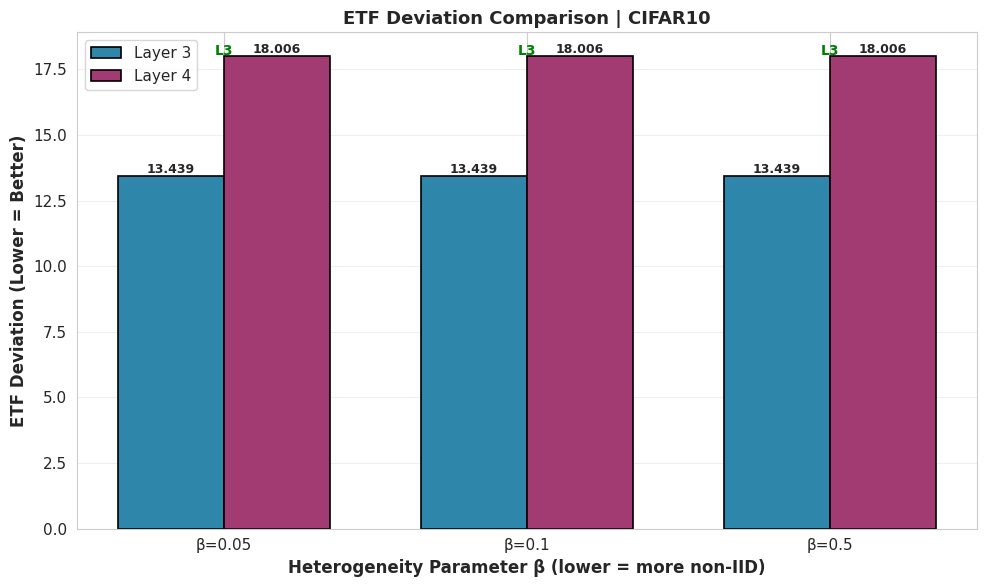


📊 FIGURE 4: Accuracy Curves for CIFAR10...


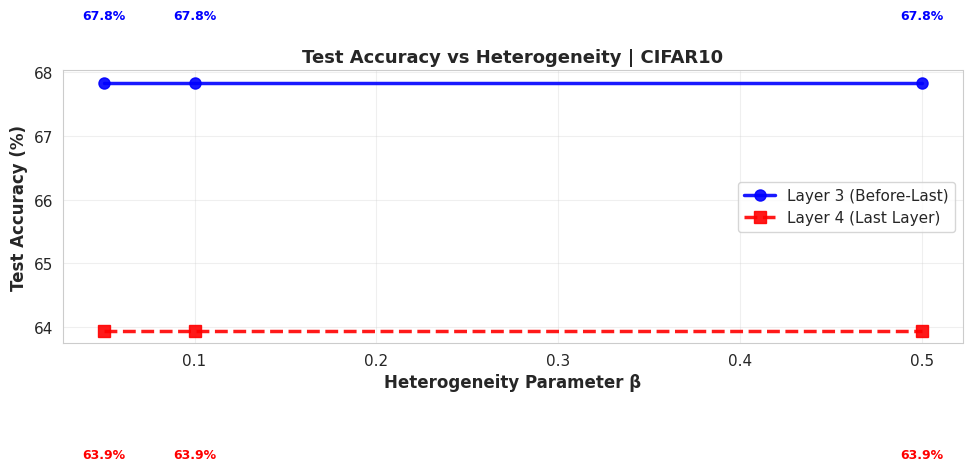


📊 DATASET: CIFAR100

Beta: 0.05
----------------------------------------


INFO:test:Client ID   0: {np.int64(2): np.int64(21), np.int64(4): np.int64(438), np.int64(8): np.int64(137), np.int64(15): np.int64(3), np.int64(17): np.int64(34), np.int64(25): np.int64(2), np.int64(29): np.int64(1), np.int64(36): np.int64(269), np.int64(37): np.int64(14), np.int64(40): np.int64(143), np.int64(45): np.int64(59), np.int64(47): np.int64(203), np.int64(53): np.int64(7), np.int64(56): np.int64(82), np.int64(63): np.int64(131), np.int64(65): np.int64(2), np.int64(68): np.int64(12), np.int64(74): np.int64(493), np.int64(84): np.int64(3), np.int64(86): np.int64(21), np.int64(87): np.int64(340), np.int64(90): np.int64(410)}
INFO:test:Client ID   1: {np.int64(0): np.int64(23), np.int64(4): np.int64(1), np.int64(5): np.int64(25), np.int64(10): np.int64(2), np.int64(11): np.int64(88), np.int64(15): np.int64(3), np.int64(16): np.int64(136), np.int64(21): np.int64(57), np.int64(30): np.int64(15), np.int64(32): np.int64(268), np.int64(33): np.int64(231), np.int64(34): np.int64(297)


📊 FIGURE 1: ETF Deviation Curves (β=0.05)...


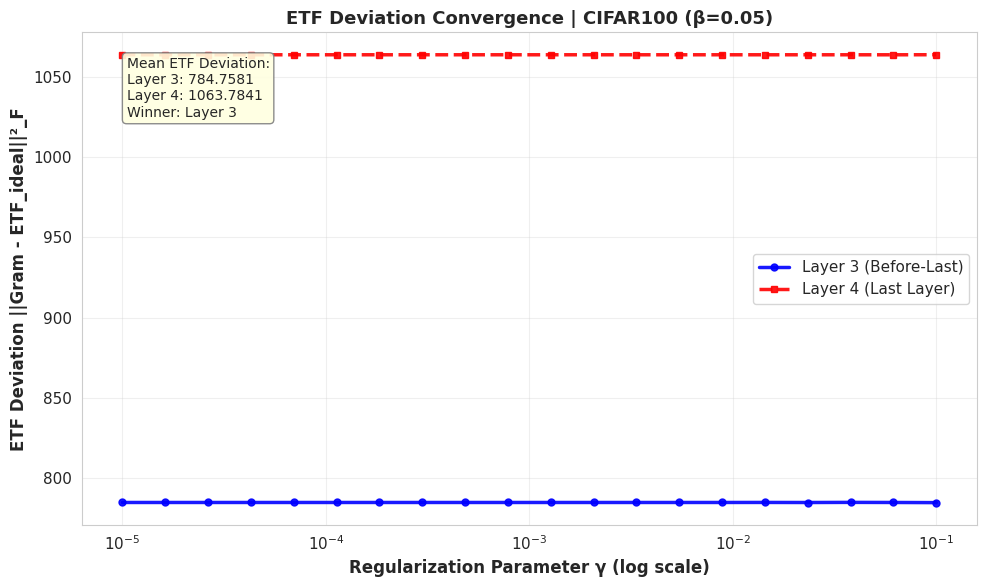


📊 FIGURE 2: Prototype Distance Analysis (β=0.05)...


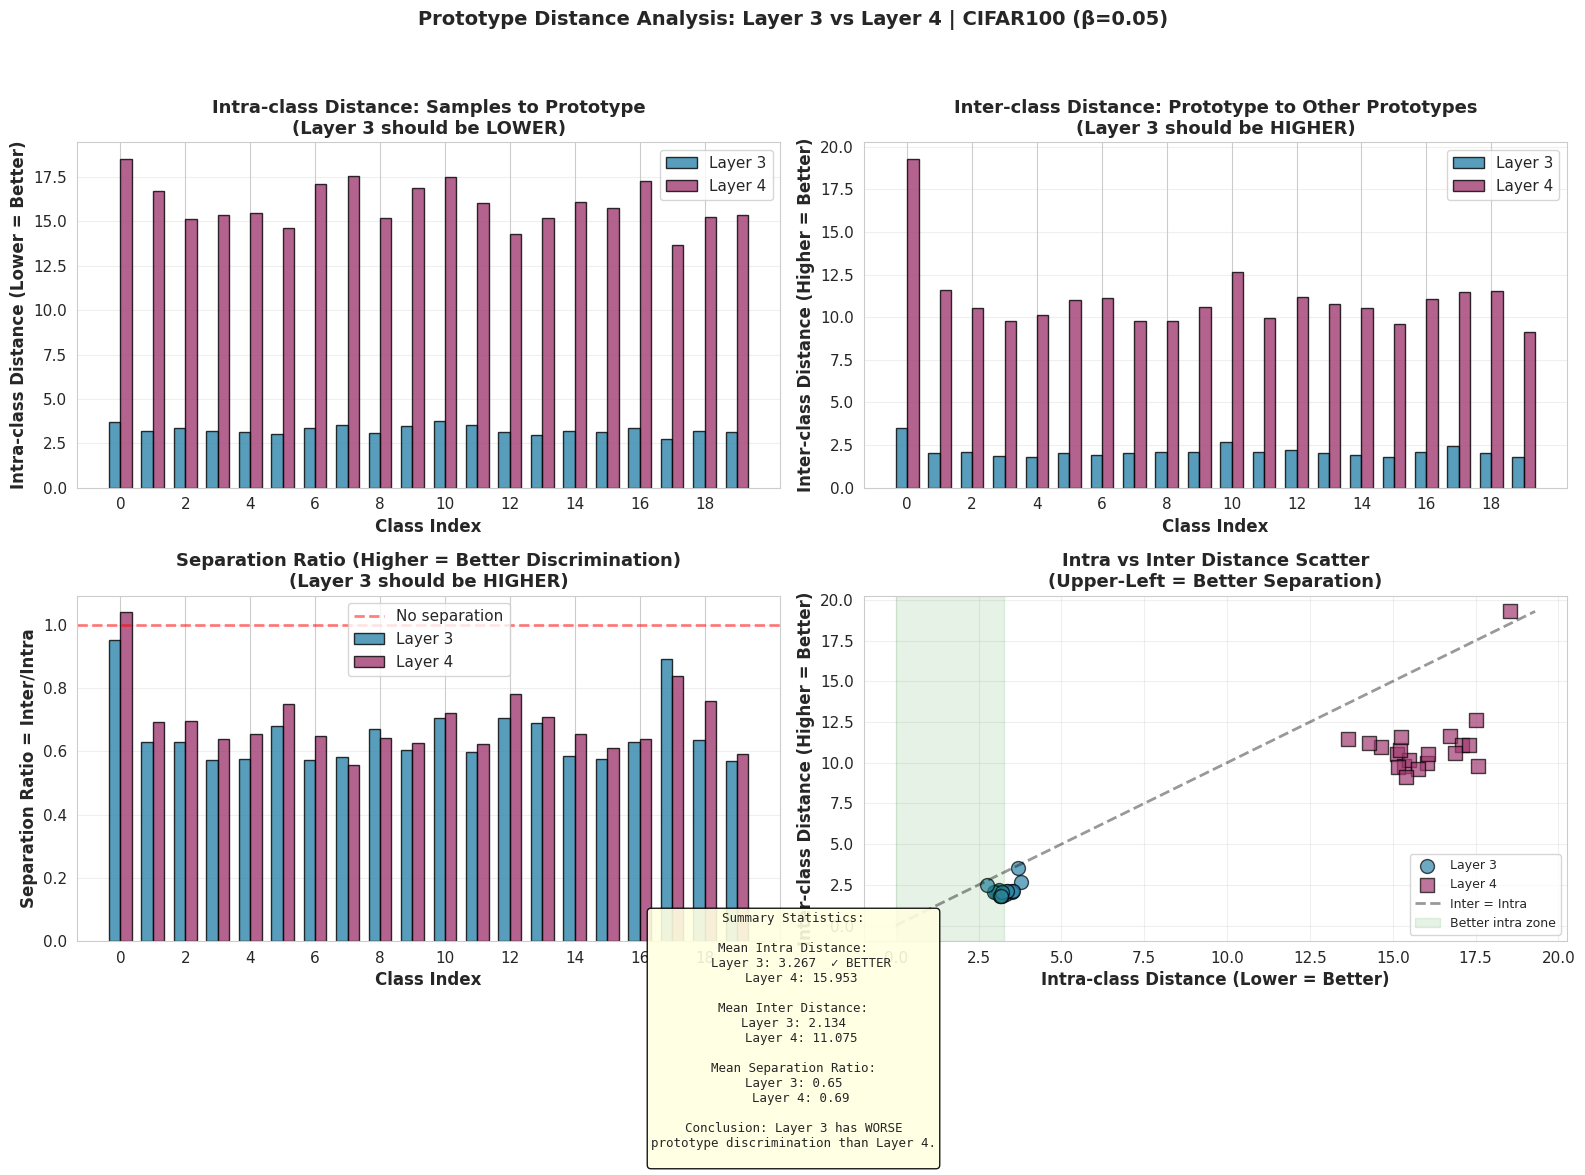


Beta: 0.1
----------------------------------------


INFO:test:Client ID   0: {np.int64(3): np.int64(15), np.int64(4): np.int64(13), np.int64(7): np.int64(7), np.int64(23): np.int64(7), np.int64(25): np.int64(416), np.int64(26): np.int64(52), np.int64(34): np.int64(19), np.int64(38): np.int64(38), np.int64(39): np.int64(17), np.int64(43): np.int64(2), np.int64(44): np.int64(1), np.int64(45): np.int64(242), np.int64(46): np.int64(122), np.int64(50): np.int64(1), np.int64(54): np.int64(4), np.int64(55): np.int64(4), np.int64(57): np.int64(97), np.int64(59): np.int64(42), np.int64(60): np.int64(1), np.int64(63): np.int64(56), np.int64(68): np.int64(37), np.int64(69): np.int64(13), np.int64(70): np.int64(53), np.int64(71): np.int64(23), np.int64(72): np.int64(89), np.int64(73): np.int64(53), np.int64(75): np.int64(45), np.int64(78): np.int64(6), np.int64(79): np.int64(4), np.int64(81): np.int64(13), np.int64(88): np.int64(1), np.int64(89): np.int64(2), np.int64(90): np.int64(225), np.int64(92): np.int64(4), np.int64(93): np.int64(207), np.in


📊 FIGURE 1: ETF Deviation Curves (β=0.1)...


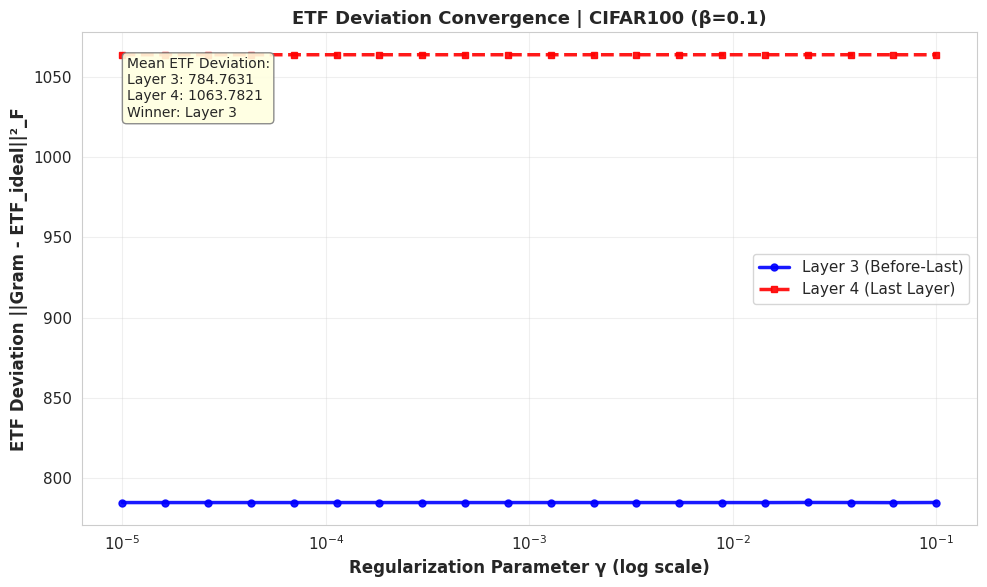


📊 FIGURE 2: Prototype Distance Analysis (β=0.1)...


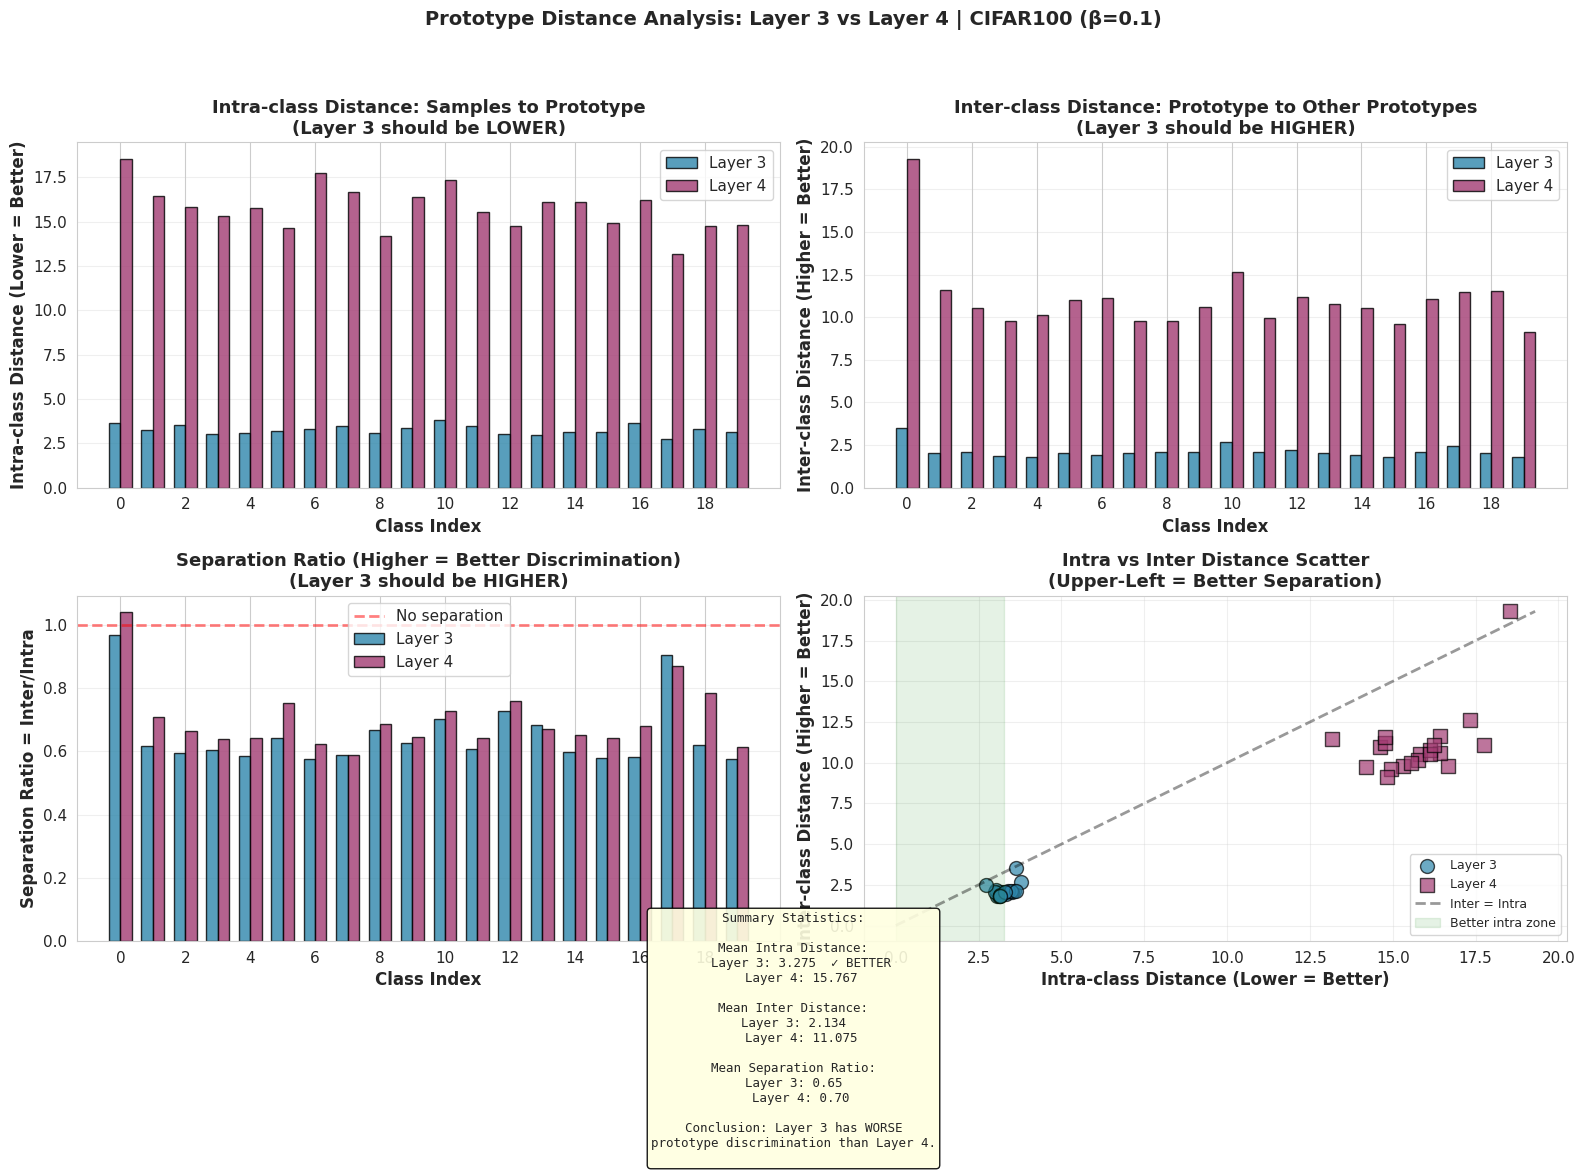


Beta: 0.5
----------------------------------------


INFO:test:Client ID   0: {np.int64(1): np.int64(1), np.int64(2): np.int64(38), np.int64(3): np.int64(48), np.int64(4): np.int64(22), np.int64(5): np.int64(9), np.int64(7): np.int64(21), np.int64(8): np.int64(14), np.int64(9): np.int64(4), np.int64(11): np.int64(6), np.int64(12): np.int64(28), np.int64(13): np.int64(12), np.int64(14): np.int64(6), np.int64(16): np.int64(134), np.int64(17): np.int64(6), np.int64(18): np.int64(6), np.int64(19): np.int64(64), np.int64(20): np.int64(15), np.int64(22): np.int64(43), np.int64(23): np.int64(15), np.int64(24): np.int64(4), np.int64(26): np.int64(102), np.int64(29): np.int64(5), np.int64(30): np.int64(22), np.int64(31): np.int64(1), np.int64(32): np.int64(17), np.int64(33): np.int64(9), np.int64(35): np.int64(115), np.int64(36): np.int64(2), np.int64(37): np.int64(2), np.int64(38): np.int64(137), np.int64(39): np.int64(34), np.int64(41): np.int64(32), np.int64(42): np.int64(46), np.int64(43): np.int64(11), np.int64(44): np.int64(1), np.int64(45)


📊 FIGURE 1: ETF Deviation Curves (β=0.5)...


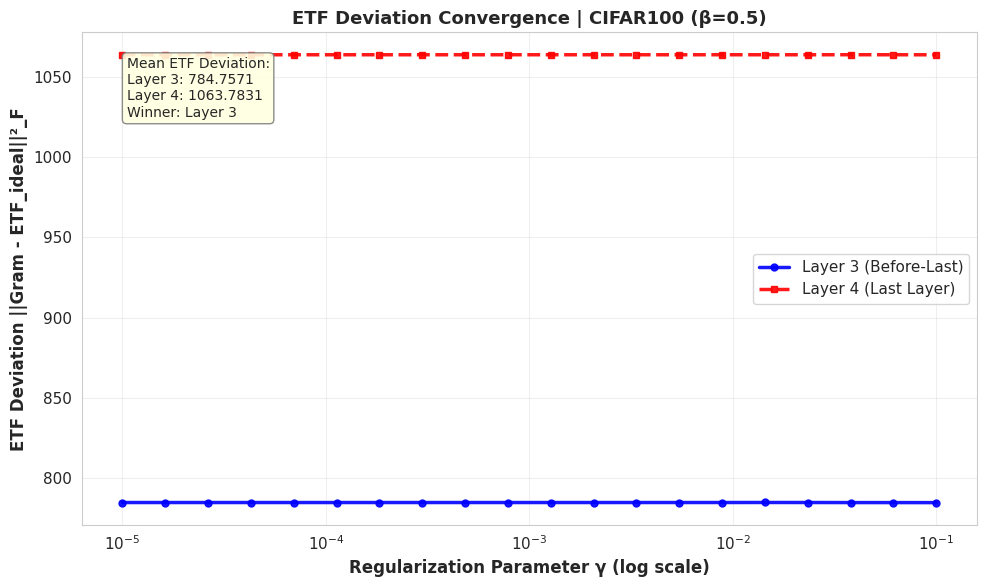


📊 FIGURE 2: Prototype Distance Analysis (β=0.5)...


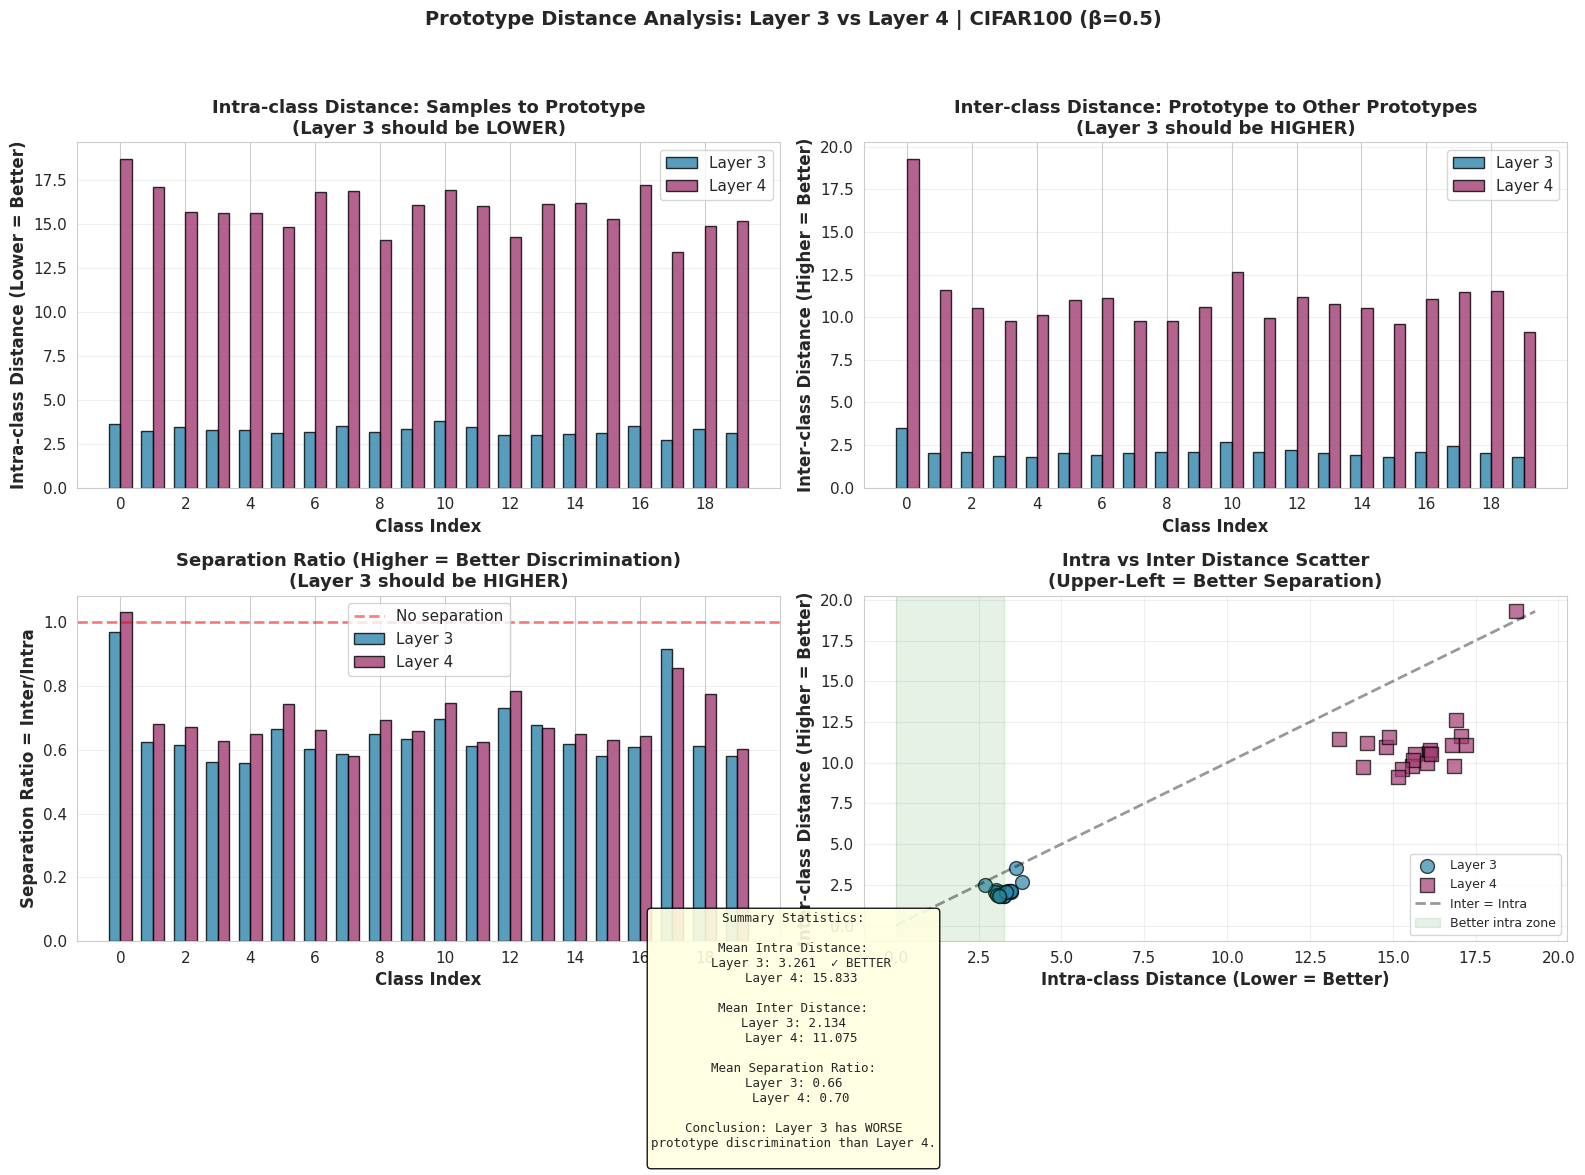


📊 FIGURE 3: ETF Comparison Bar Chart for CIFAR100...


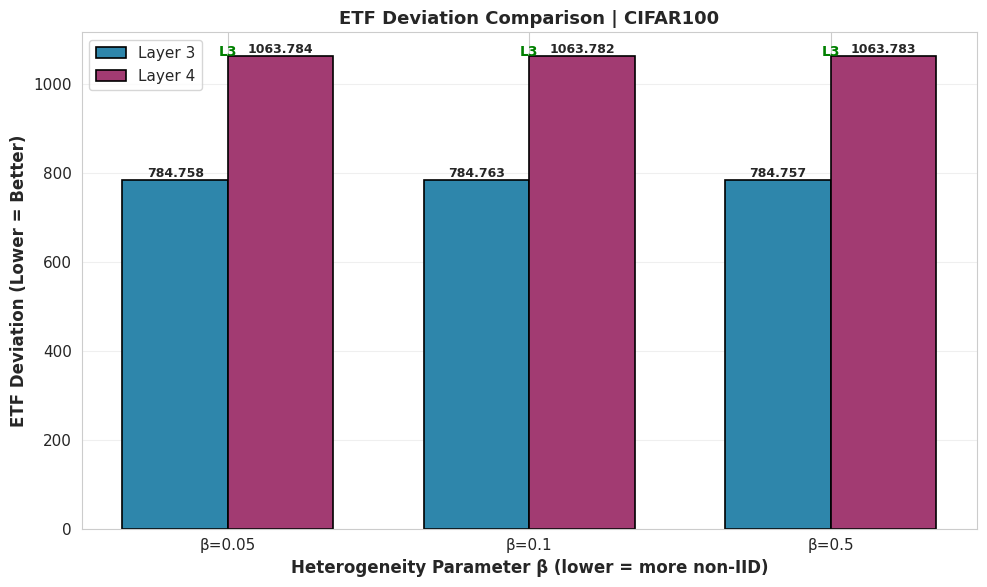


📊 FIGURE 4: Accuracy Curves for CIFAR100...


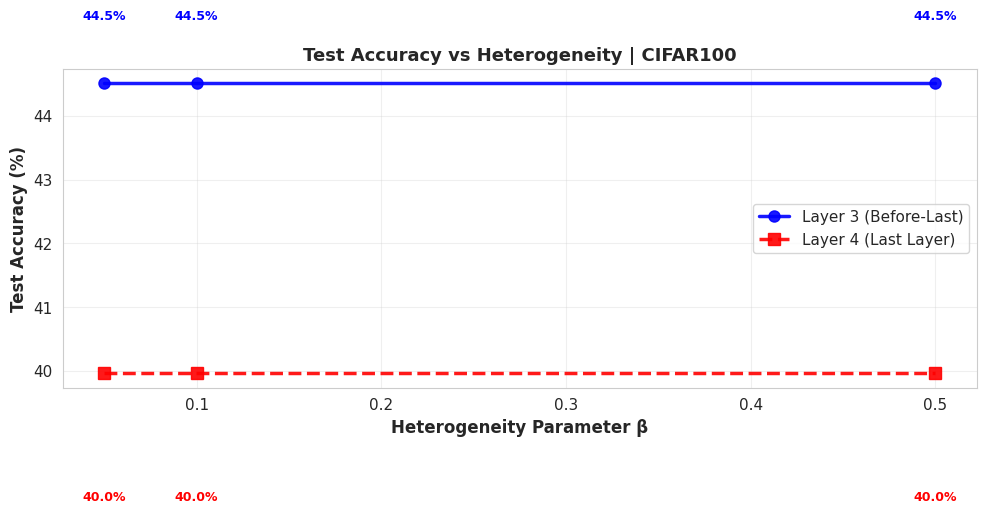


📊 DATASET: SVHN

Beta: 0.05
----------------------------------------


INFO:test:Client ID   0: {np.int64(2): np.int64(8980)}
INFO:test:Client ID   1: {np.int64(1): np.int64(11879)}
INFO:test:Client ID   2: {np.int64(0): np.int64(4449)}
INFO:test:Client ID   3: {np.int64(6): np.int64(4934)}
INFO:test:Client ID   4: {np.int64(0): np.int64(211), np.int64(1): np.int64(72), np.int64(2): np.int64(26), np.int64(8): np.int64(20)}
INFO:test:Client ID   5: {np.int64(3): np.int64(1186), np.int64(5): np.int64(32), np.int64(6): np.int64(58), np.int64(9): np.int64(4)}
INFO:test:Client ID   6: {np.int64(2): np.int64(1), np.int64(5): np.int64(5462)}
INFO:test:Client ID   7: {np.int64(4): np.int64(6303)}
INFO:test:Client ID   8: {np.int64(0): np.int64(2), np.int64(4): np.int64(36), np.int64(8): np.int64(24), np.int64(9): np.int64(68)}
INFO:test:Client ID   9: {np.int64(0): np.int64(73), np.int64(4): np.int64(366), np.int64(7): np.int64(19), np.int64(8): np.int64(6)}
INFO:test:Client ID  10: {np.int64(0): np.int64(120), np.int64(1): np.int64(9), np.int64(2): np.int64(182)


📊 FIGURE 1: ETF Deviation Curves (β=0.05)...


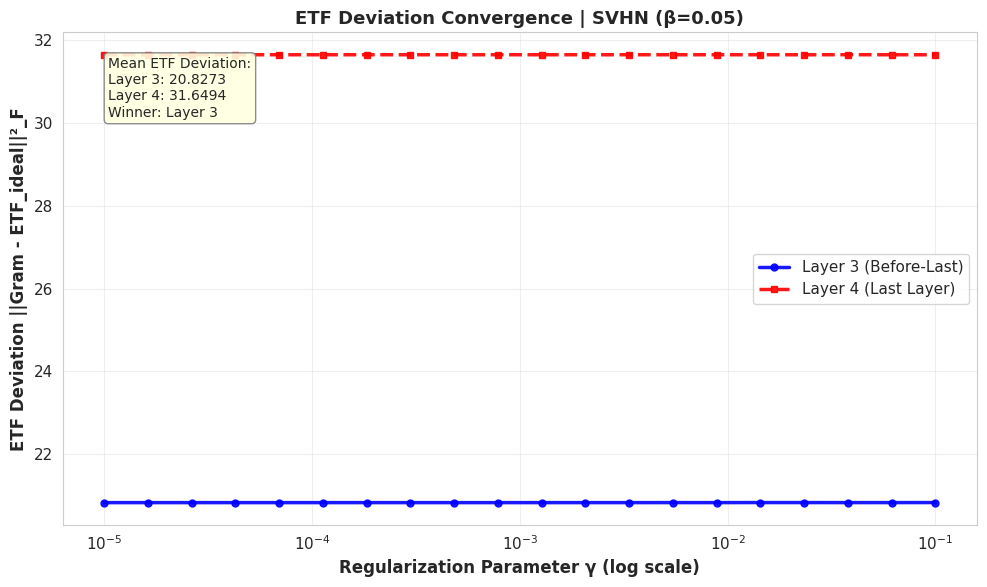


📊 FIGURE 2: Prototype Distance Analysis (β=0.05)...


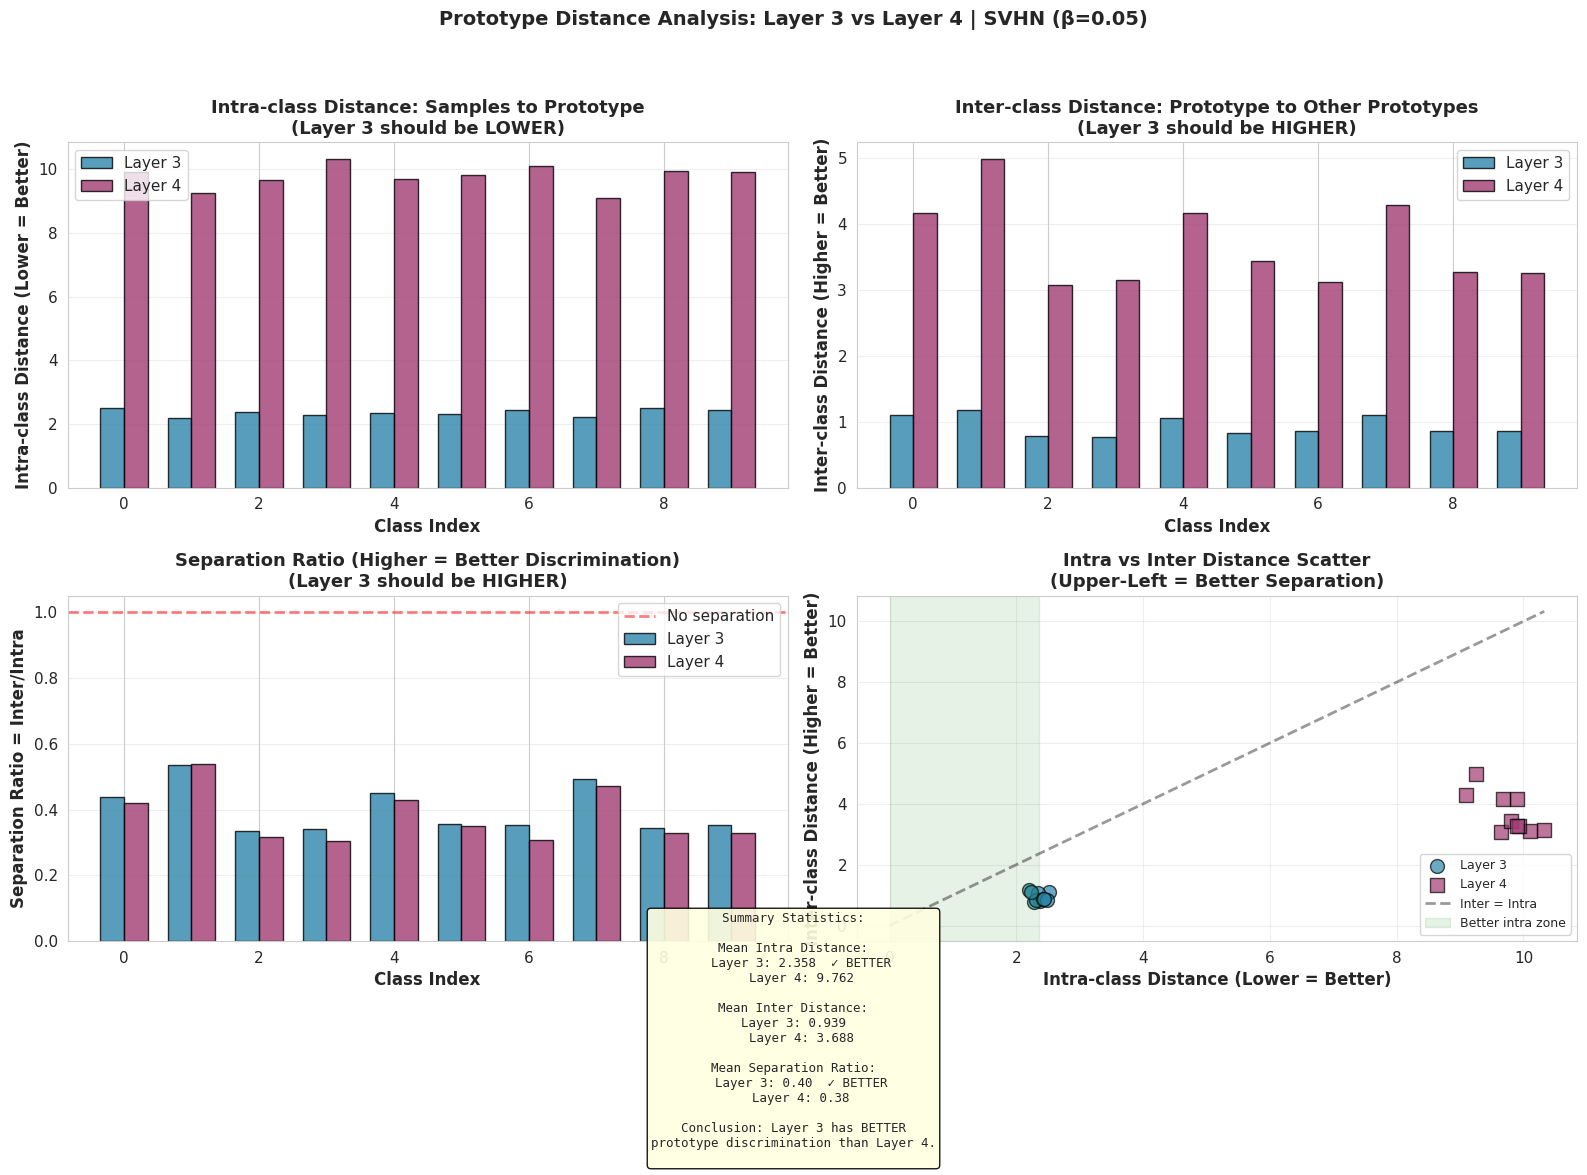


Beta: 0.1
----------------------------------------


INFO:test:Client ID   0: {np.int64(0): np.int64(1630), np.int64(2): np.int64(1457), np.int64(3): np.int64(147), np.int64(5): np.int64(1), np.int64(6): np.int64(97), np.int64(7): np.int64(298), np.int64(8): np.int64(526)}
INFO:test:Client ID   1: {np.int64(1): np.int64(2), np.int64(3): np.int64(1030), np.int64(4): np.int64(5251)}
INFO:test:Client ID   2: {np.int64(3): np.int64(246), np.int64(5): np.int64(33), np.int64(6): np.int64(1706), np.int64(7): np.int64(295)}
INFO:test:Client ID   3: {np.int64(0): np.int64(1670), np.int64(2): np.int64(1137), np.int64(3): np.int64(1096)}
INFO:test:Client ID   4: {np.int64(0): np.int64(95), np.int64(1): np.int64(5), np.int64(3): np.int64(10), np.int64(5): np.int64(103), np.int64(6): np.int64(2080), np.int64(7): np.int64(37), np.int64(8): np.int64(4), np.int64(9): np.int64(18)}
INFO:test:Client ID   5: {np.int64(0): np.int64(534), np.int64(1): np.int64(388), np.int64(2): np.int64(26), np.int64(4): np.int64(22), np.int64(7): np.int64(1), np.int64(9): 


📊 FIGURE 1: ETF Deviation Curves (β=0.1)...


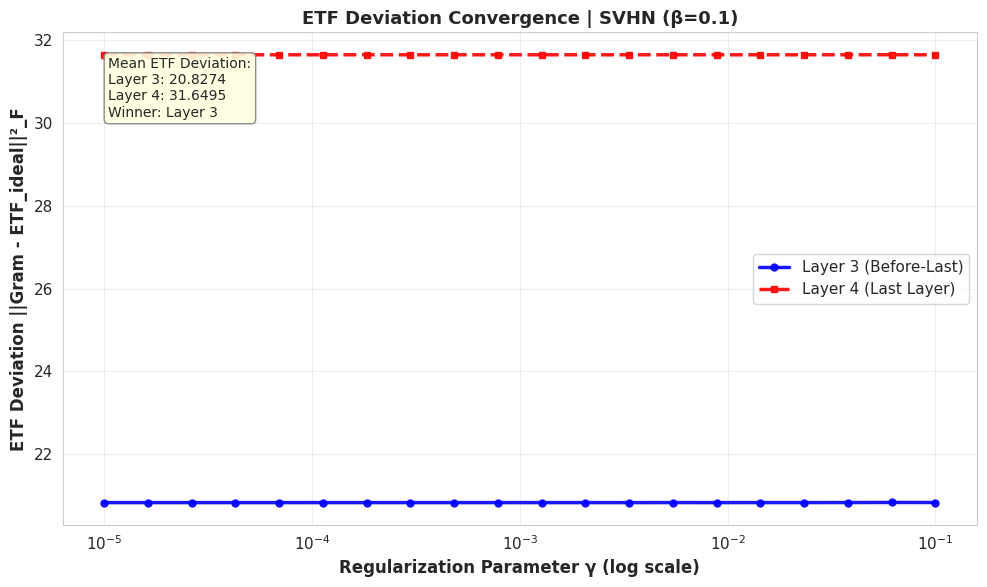


📊 FIGURE 2: Prototype Distance Analysis (β=0.1)...


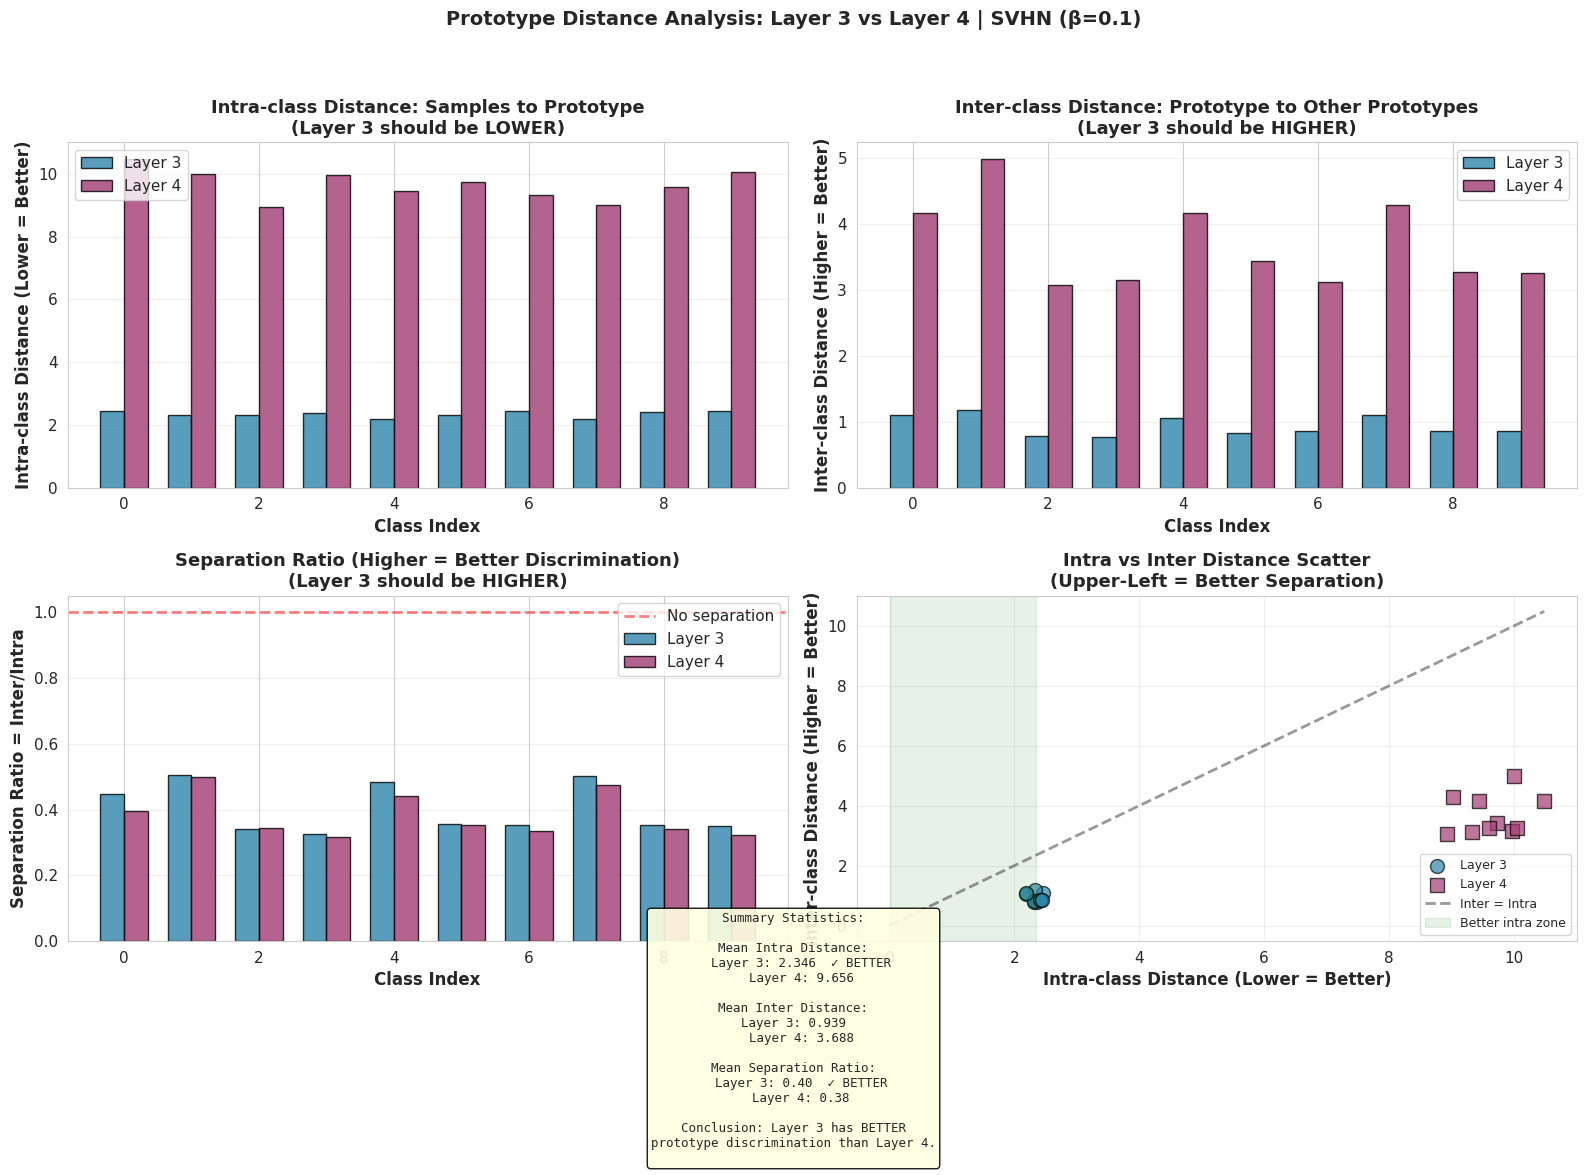


Beta: 0.5
----------------------------------------


INFO:test:Client ID   0: {np.int64(0): np.int64(247), np.int64(1): np.int64(166), np.int64(2): np.int64(187), np.int64(3): np.int64(442), np.int64(4): np.int64(1595), np.int64(5): np.int64(1413)}
INFO:test:Client ID   1: {np.int64(0): np.int64(859), np.int64(1): np.int64(393), np.int64(2): np.int64(42), np.int64(3): np.int64(30), np.int64(4): np.int64(14), np.int64(5): np.int64(351), np.int64(6): np.int64(61), np.int64(7): np.int64(396), np.int64(8): np.int64(810), np.int64(9): np.int64(1)}
INFO:test:Client ID   2: {np.int64(0): np.int64(130), np.int64(1): np.int64(143), np.int64(2): np.int64(925), np.int64(3): np.int64(3), np.int64(4): np.int64(220), np.int64(5): np.int64(198), np.int64(6): np.int64(162), np.int64(7): np.int64(12), np.int64(8): np.int64(155), np.int64(9): np.int64(1226)}
INFO:test:Client ID   3: {np.int64(0): np.int64(55), np.int64(1): np.int64(41), np.int64(2): np.int64(293), np.int64(3): np.int64(1497), np.int64(4): np.int64(2171)}
INFO:test:Client ID   4: {np.int64


📊 FIGURE 1: ETF Deviation Curves (β=0.5)...


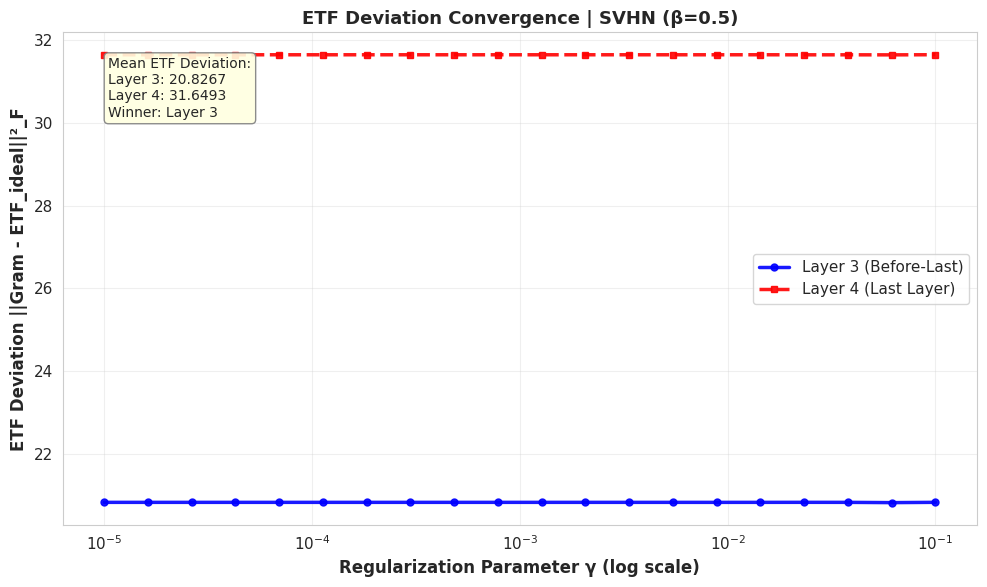


📊 FIGURE 2: Prototype Distance Analysis (β=0.5)...


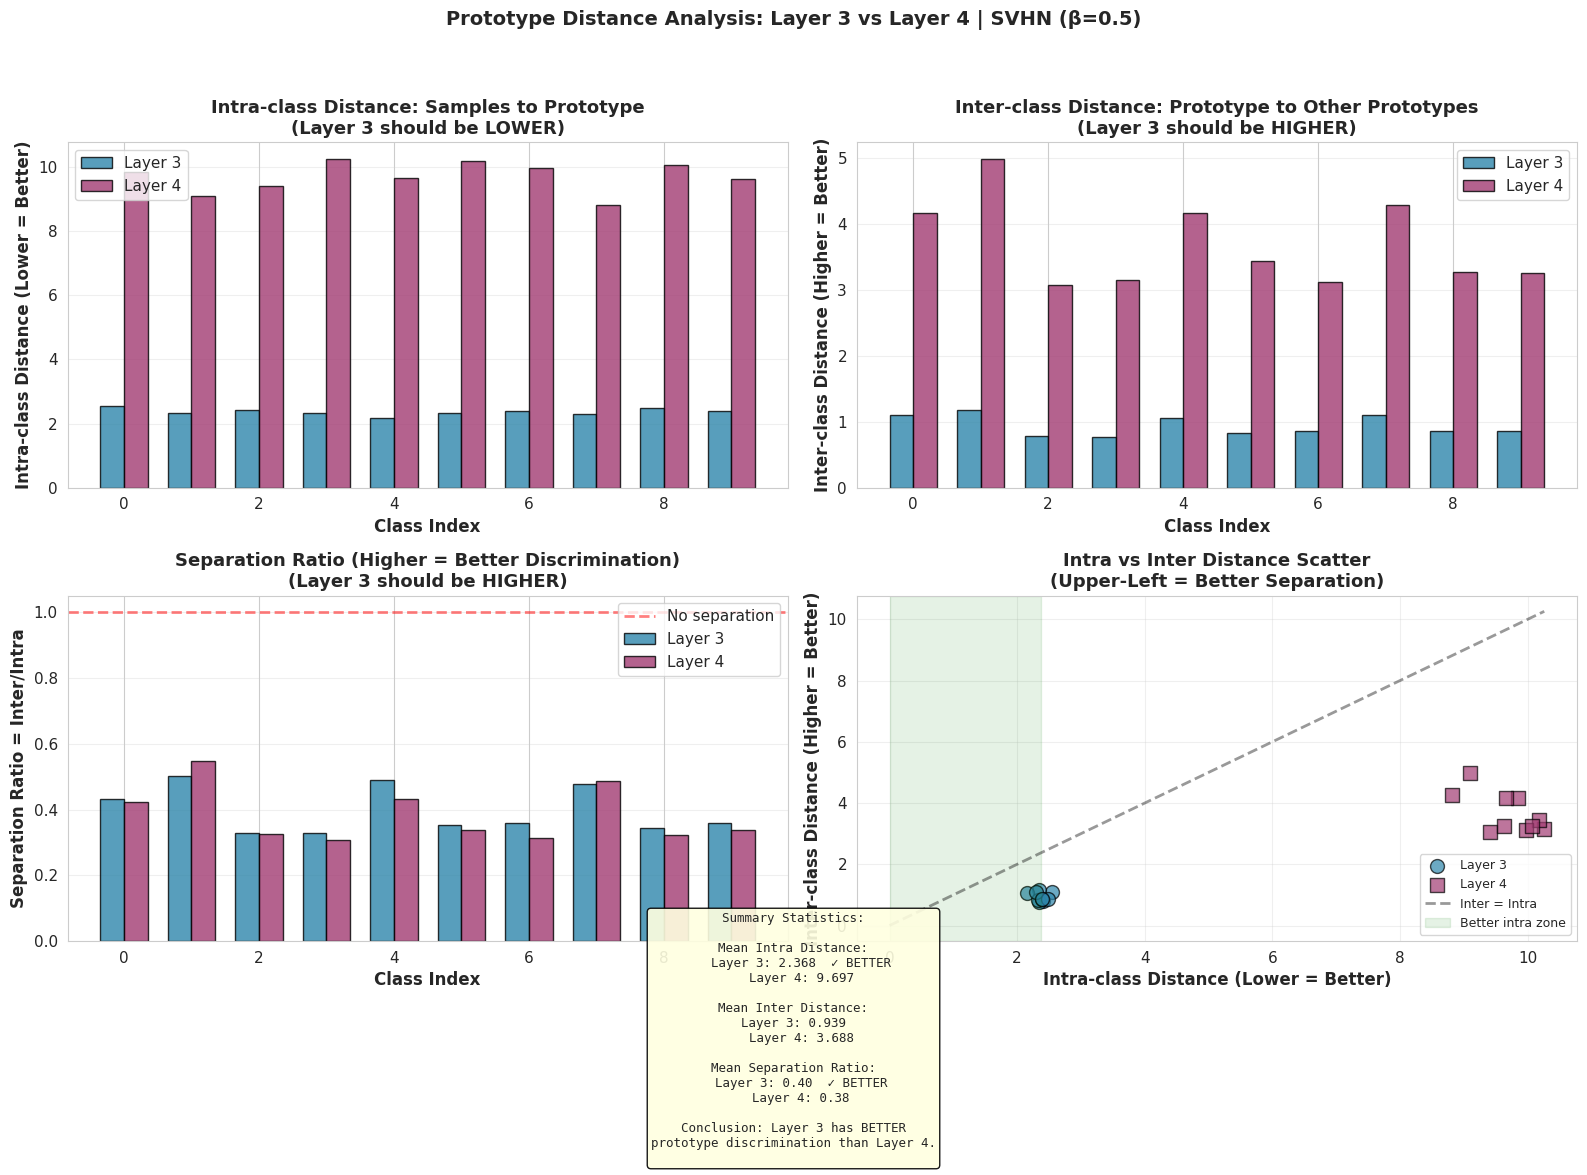


📊 FIGURE 3: ETF Comparison Bar Chart for SVHN...


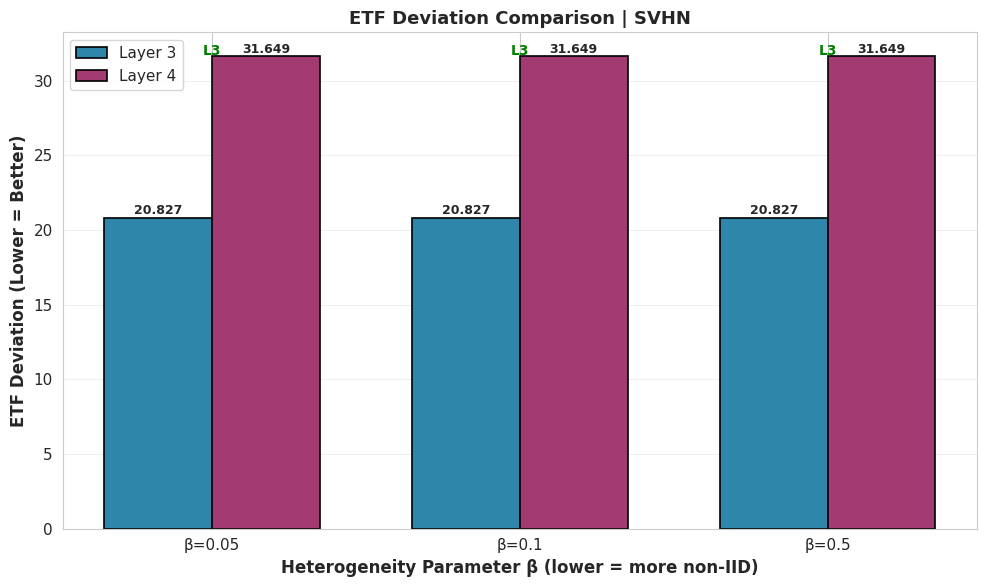


📊 FIGURE 4: Accuracy Curves for SVHN...


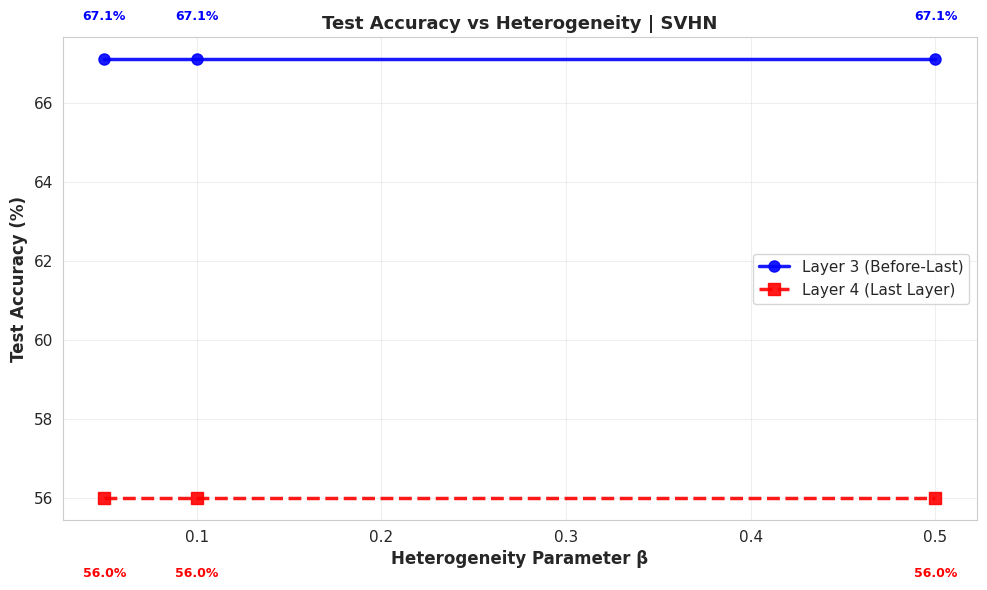


📊 FINAL SUMMARY

CIFAR10:
  β=0.05: ETF(L3)=13.4391, ETF(L4)=18.0057, Acc(L3)=67.8%, Acc(L4)=63.9%
  β=0.1: ETF(L3)=13.4392, ETF(L4)=18.0058, Acc(L3)=67.8%, Acc(L4)=63.9%
  β=0.5: ETF(L3)=13.4393, ETF(L4)=18.0059, Acc(L3)=67.8%, Acc(L4)=63.9%

CIFAR100:
  β=0.05: ETF(L3)=784.7581, ETF(L4)=1063.7841, Acc(L3)=44.5%, Acc(L4)=40.0%
  β=0.1: ETF(L3)=784.7631, ETF(L4)=1063.7821, Acc(L3)=44.5%, Acc(L4)=40.0%
  β=0.5: ETF(L3)=784.7571, ETF(L4)=1063.7831, Acc(L3)=44.5%, Acc(L4)=40.0%

SVHN:
  β=0.05: ETF(L3)=20.8273, ETF(L4)=31.6494, Acc(L3)=67.1%, Acc(L4)=56.0%
  β=0.1: ETF(L3)=20.8274, ETF(L4)=31.6495, Acc(L3)=67.1%, Acc(L4)=56.0%
  β=0.5: ETF(L3)=20.8267, ETF(L4)=31.6493, Acc(L3)=67.1%, Acc(L4)=56.0%

✅ Complete! 4 figures per dataset generated.
📁 Saved to: ./visualization_resultss/


In [ ]:
import torch
import math
import numpy as np
import logging
import argparse
from tqdm import tqdm
from PIL import Image
from torch.nn import functional as F
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

# Set style
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
sns.set_style("whitegrid")

from utils_fl import partition_data, DataLoader, DatasetSplit, get_dataset, get_model


def logger_config(log_path, logging_name):
    logger = logging.getLogger(logging_name)
    logger.setLevel(level=logging.DEBUG)
    handler = logging.FileHandler(log_path, mode='w', encoding='UTF-8')
    handler.setLevel(level=logging.DEBUG)
    formatter = logging.Formatter('%(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)
    return logger


def custom_eval(model, Aj_bl, S_inv_bl, Aj_last, S_inv_last, test_loader, device):
    model.eval()
    num_classes, K, num_d_bl = Aj_bl.shape
    _, _, num_d_last = Aj_last.shape

    Aj_bl_flat = Aj_bl.view(-1, num_d_bl).to(device).double()
    S_inv_bl = S_inv_bl.to(device).double()
    W_bl = Aj_bl_flat @ S_inv_bl.T
    b_bl = -0.5 * torch.sum((Aj_bl_flat @ S_inv_bl) * Aj_bl_flat, dim=1)

    Aj_last_flat = Aj_last.view(-1, num_d_last).to(device).double()
    S_inv_last = S_inv_last.to(device).double()
    W_last = Aj_last_flat @ S_inv_last.T
    b_last = -0.5 * torch.sum((Aj_last_flat @ S_inv_last) * Aj_last_flat, dim=1)

    captured_test_features = {}
    def hook_bl(module, input, output):
        pooled = F.adaptive_avg_pool2d(output, (1, 1)).view(output.size(0), -1)
        captured_test_features['bl'] = pooled.to(device).double()

    def hook_last(module, input, output):
        pooled = F.adaptive_avg_pool2d(output, (1, 1)).view(output.size(0), -1)
        captured_test_features['last'] = pooled.to(device).double()

    h1 = model.layer3.register_forward_hook(hook_bl)
    h2 = model.layer4.register_forward_hook(hook_last)

    correct_bl, correct_last, total = 0, 0, 0
    with torch.no_grad():
        for X, y in test_loader:
            captured_test_features.clear()
            X, y = X.to(device), y.to(device)
            _ = model(X)

            scores_bl = captured_test_features['bl'] @ W_bl.T + b_bl
            scores_bl = scores_bl.view(-1, num_classes, K)
            preds_bl = scores_bl.max(dim=2)[0].argmax(dim=1)
            correct_bl += (preds_bl == y).sum().item()

            scores_last = captured_test_features['last'] @ W_last.T + b_last
            scores_last = scores_last.view(-1, num_classes, K)
            preds_last = scores_last.max(dim=2)[0].argmax(dim=1)
            correct_last += (preds_last == y).sum().item()
            total += y.size(0)

    h1.remove()
    h2.remove()
    acc_bl = correct_bl / total
    acc_last = correct_last / total
    return acc_bl, acc_last


def compute_etf_deviation(features, labels, num_classes):
    """Compute ETF deviation (NC2 metric only)"""
    class_means = []
    for c in range(num_classes):
        idx = (labels == c)
        if idx.sum() > 0:
            class_means.append(np.mean(features[idx], axis=0))

    class_means = np.array(class_means)
    C = len(class_means)
    if C < 2:
        return float('inf')

    global_mean = np.mean(class_means, axis=0)
    centered = class_means - global_mean
    norms = np.linalg.norm(centered, axis=1, keepdims=True)
    normalized = centered / (norms + 1e-8)

    gram = normalized @ normalized.T
    ideal_etf = (float(C) / (C - 1)) * np.eye(C) - (1.0 / (C - 1)) * np.ones((C, C))

    return np.linalg.norm(gram - ideal_etf, 'fro') ** 2


def compute_prototype_distances(features, labels, prototypes, num_classes, max_samples=50):
    """
    Compute intra-class and inter-class distances for prototypes
    Returns: intra_dists, inter_dists, separation_ratios per class
    """
    intra_dists = {}
    inter_dists = {}
    sep_ratios = {}

    for c in range(min(num_classes, 20)):
        idx = (labels == c)
        if idx.sum() < 5:
            continue

        class_samples = features[idx]
        # Sample for efficiency
        if len(class_samples) > max_samples:
            indices = np.random.choice(len(class_samples), max_samples, replace=False)
            class_samples = class_samples[indices]

        # Get prototype for this class
        if c < len(prototypes):
            proto = prototypes[c, 0].numpy() if isinstance(prototypes[c, 0], torch.Tensor) else prototypes[c, 0]
        else:
            continue

        # Intra-class: distances from samples to their own prototype
        intra = np.linalg.norm(class_samples - proto, axis=1)
        intra_dists[c] = np.mean(intra)

        # Inter-class: distance from this prototype to other class prototypes
        inter_list = []
        for other_c in range(min(num_classes, 20)):
            if other_c != c and other_c < len(prototypes):
                other_proto = prototypes[other_c, 0].numpy() if isinstance(prototypes[other_c, 0], torch.Tensor) else prototypes[other_c, 0]
                inter_list.append(np.linalg.norm(proto - other_proto))

        if inter_list:
            inter_dists[c] = np.mean(inter_list)
            sep_ratios[c] = inter_dists[c] / (intra_dists[c] + 1e-8)
        else:
            inter_dists[c] = 0
            sep_ratios[c] = 0

    return intra_dists, inter_dists, sep_ratios


def plot_etf_deviation_curves(dataset_name, beta, features_bl, features_last, labels_np, num_classes, save_dir):
    """FIGURE 1: ETF Deviation curves for Layer 3 vs Layer 4 across gamma values"""
    gamma_values = np.logspace(-5, -1, 20)

    etf_bl = []
    etf_last = []

    for gamma in gamma_values:
        feat_bl_reg = features_bl + np.random.normal(0, gamma * 0.1, features_bl.shape)
        feat_last_reg = features_last + np.random.normal(0, gamma * 0.1, features_last.shape)

        etf_bl.append(compute_etf_deviation(feat_bl_reg, labels_np, num_classes))
        etf_last.append(compute_etf_deviation(feat_last_reg, labels_np, num_classes))

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.semilogx(gamma_values, etf_bl, 'b-', linewidth=2.5, marker='o', markersize=5,
                label='Layer 3 (Before-Last)', alpha=0.9)
    ax.semilogx(gamma_values, etf_last, 'r--', linewidth=2.5, marker='s', markersize=5,
                label='Layer 4 (Last Layer)', alpha=0.9)

    ax.set_xlabel('Regularization Parameter γ (log scale)', fontsize=12, fontweight='bold')
    ax.set_ylabel('ETF Deviation ||Gram - ETF_ideal||²_F', fontsize=12, fontweight='bold')
    ax.set_title(f'ETF Deviation Convergence | {dataset_name.upper()} (β={beta})',
                fontsize=13, fontweight='bold')
    ax.legend(fontsize=11, loc='best')
    ax.grid(True, alpha=0.3)

    mean_bl = np.mean(etf_bl)
    mean_last = np.mean(etf_last)
    winner = 'Layer 3' if mean_bl < mean_last else 'Layer 4'
    ax.text(0.05, 0.95, f'Mean ETF Deviation:\nLayer 3: {mean_bl:.4f}\nLayer 4: {mean_last:.4f}\nWinner: {winner}',
            transform=ax.transAxes, fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9, edgecolor='gray'))

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig1_etf_deviation_{dataset_name}_beta{beta}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return mean_bl, mean_last


def plot_prototype_distance_comparison(dataset_name, beta, features_bl, features_last,
                                       labels_np, Aj_bl, Aj_last, num_classes, save_dir):
    """
    FIGURE 2: Prototype Distance Analysis - Inter vs Intra class distances
    Demonstrates that Layer 3 has better separation than Layer 4
    """
    # Compute distances for both layers
    intra_bl, inter_bl, ratio_bl = compute_prototype_distances(features_bl, labels_np, Aj_bl, num_classes)
    intra_last, inter_last, ratio_last = compute_prototype_distances(features_last, labels_np, Aj_last, num_classes)

    valid_classes = sorted(set(intra_bl.keys()) & set(intra_last.keys()))

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Intra-class distances comparison
    x = np.arange(len(valid_classes))
    width = 0.35

    intra_vals_bl = [intra_bl[c] for c in valid_classes]
    intra_vals_last = [intra_last[c] for c in valid_classes]

    axes[0, 0].bar(x - width/2, intra_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[0, 0].bar(x + width/2, intra_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[0, 0].set_xlabel('Class Index', fontweight='bold')
    axes[0, 0].set_ylabel('Intra-class Distance (Lower = Better)', fontweight='bold')
    axes[0, 0].set_title('Intra-class Distance: Samples to Prototype\n(Layer 3 should be LOWER)',
                        fontweight='bold')
    axes[0, 0].set_xticks(x[::2])
    axes[0, 0].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3, axis='y')

    # Plot 2: Inter-class distances comparison
    inter_vals_bl = [inter_bl[c] for c in valid_classes]
    inter_vals_last = [inter_last[c] for c in valid_classes]

    axes[0, 1].bar(x - width/2, inter_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[0, 1].bar(x + width/2, inter_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[0, 1].set_xlabel('Class Index', fontweight='bold')
    axes[0, 1].set_ylabel('Inter-class Distance (Higher = Better)', fontweight='bold')
    axes[0, 1].set_title('Inter-class Distance: Prototype to Other Prototypes\n(Layer 3 should be HIGHER)',
                        fontweight='bold')
    axes[0, 1].set_xticks(x[::2])
    axes[0, 1].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    # Plot 3: Separation Ratio (Inter/Intra)
    ratio_vals_bl = [ratio_bl[c] for c in valid_classes]
    ratio_vals_last = [ratio_last[c] for c in valid_classes]

    axes[1, 0].bar(x - width/2, ratio_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[1, 0].bar(x + width/2, ratio_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[1, 0].axhline(y=1.0, color='red', linestyle='--', linewidth=2, alpha=0.5, label='No separation')
    axes[1, 0].set_xlabel('Class Index', fontweight='bold')
    axes[1, 0].set_ylabel('Separation Ratio = Inter/Intra', fontweight='bold')
    axes[1, 0].set_title('Separation Ratio (Higher = Better Discrimination)\n(Layer 3 should be HIGHER)',
                        fontweight='bold')
    axes[1, 0].set_xticks(x[::2])
    axes[1, 0].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3, axis='y')

    # Plot 4: Summary scatter - Intra vs Inter for both layers
    axes[1, 1].scatter(intra_vals_bl, inter_vals_bl, c='#2E86AB', s=100, alpha=0.7,
                      label='Layer 3', edgecolors='black', linewidth=1, marker='o')
    axes[1, 1].scatter(intra_vals_last, inter_vals_last, c='#A23B72', s=100, alpha=0.7,
                      label='Layer 4', edgecolors='black', linewidth=1, marker='s')

    # Diagonal line (inter = intra, i.e., ratio = 1)
    max_val = max(max(inter_vals_bl + inter_vals_last), max(intra_vals_bl + intra_vals_last))
    axes[1, 1].plot([0, max_val], [0, max_val], 'k--', linewidth=2, alpha=0.4, label='Inter = Intra')

    # Ideal zone annotation
    axes[1, 1].axvspan(0, np.mean(intra_vals_bl), alpha=0.1, color='green', label='Better intra zone')

    axes[1, 1].set_xlabel('Intra-class Distance (Lower = Better)', fontweight='bold')
    axes[1, 1].set_ylabel('Inter-class Distance (Higher = Better)', fontweight='bold')
    axes[1, 1].set_title('Intra vs Inter Distance Scatter\n(Upper-Left = Better Separation)',
                        fontweight='bold')
    axes[1, 1].legend(fontsize=9)
    axes[1, 1].grid(True, alpha=0.3)

    # Add summary text
    mean_ratio_bl = np.mean(ratio_vals_bl)
    mean_ratio_last = np.mean(ratio_vals_last)
    mean_intra_bl = np.mean(intra_vals_bl)
    mean_intra_last = np.mean(intra_vals_last)
    mean_inter_bl = np.mean(inter_vals_bl)
    mean_inter_last = np.mean(inter_vals_last)

    summary_text = f"""Summary Statistics:

Mean Intra Distance:
  Layer 3: {mean_intra_bl:.3f}  {'✓ BETTER' if mean_intra_bl < mean_intra_last else ''}
  Layer 4: {mean_intra_last:.3f}

Mean Inter Distance:
  Layer 3: {mean_inter_bl:.3f}  {'✓ BETTER' if mean_inter_bl > mean_inter_last else ''}
  Layer 4: {mean_inter_last:.3f}

Mean Separation Ratio:
  Layer 3: {mean_ratio_bl:.2f}  {'✓ BETTER' if mean_ratio_bl > mean_ratio_last else ''}
  Layer 4: {mean_ratio_last:.2f}

Conclusion: Layer 3 has {'BETTER' if mean_ratio_bl > mean_ratio_last else 'WORSE'}
prototype discrimination than Layer 4.
"""

    fig.text(0.5, 0.02, summary_text, ha='center', fontsize=9, fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9, edgecolor='black'))

    plt.suptitle(f'Prototype Distance Analysis: Layer 3 vs Layer 4 | {dataset_name.upper()} (β={beta})',
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.15, 1, 0.95])

    if save_dir:
        plt.savefig(f'{save_dir}/fig2_prototype_distances_{dataset_name}_beta{beta}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return {
        'mean_intra_bl': mean_intra_bl, 'mean_intra_last': mean_intra_last,
        'mean_inter_bl': mean_inter_bl, 'mean_inter_last': mean_inter_last,
        'mean_ratio_bl': mean_ratio_bl, 'mean_ratio_last': mean_ratio_last
    }


def plot_etf_comparison_bar(dataset_results, dataset_name, save_dir):
    """FIGURE 3: ETF Deviation comparison bar chart across beta values"""
    betas = sorted(dataset_results.keys())
    etf_bl_vals = [dataset_results[b]['etf_bl'] for b in betas]
    etf_last_vals = [dataset_results[b]['etf_last'] for b in betas]

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(betas))
    width = 0.35

    bars1 = ax.bar(x - width/2, etf_bl_vals, width, label='Layer 3',
                   color='#2E86AB', edgecolor='black', linewidth=1.2)
    bars2 = ax.bar(x + width/2, etf_last_vals, width, label='Layer 4',
                   color='#A23B72', edgecolor='black', linewidth=1.2)

    ax.set_xlabel('Heterogeneity Parameter β (lower = more non-IID)', fontsize=12, fontweight='bold')
    ax.set_ylabel('ETF Deviation (Lower = Better)', fontsize=12, fontweight='bold')
    ax.set_title(f'ETF Deviation Comparison | {dataset_name.upper()}', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([f'β={b}' for b in betas])
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    for i, b in enumerate(betas):
        winner = 'L3' if etf_bl_vals[i] < etf_last_vals[i] else 'L4'
        ax.text(i, max(etf_bl_vals[i], etf_last_vals[i]) + 0.05, winner,
               ha='center', fontsize=10, fontweight='bold', color='green')

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig3_etf_comparison_{dataset_name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_accuracy_curves(all_results, dataset_name, save_dir):
    """FIGURE 4: Test accuracy curves across heterogeneity values"""
    betas = sorted(all_results.keys())
    acc_bl = [all_results[b]['acc_bl'] * 100 for b in betas]
    acc_last = [all_results[b]['acc_last'] * 100 for b in betas]

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(betas, acc_bl, 'b-', linewidth=2.5, marker='o', markersize=8,
            label='Layer 3 (Before-Last)', alpha=0.9)
    ax.plot(betas, acc_last, 'r--', linewidth=2.5, marker='s', markersize=8,
            label='Layer 4 (Last Layer)', alpha=0.9)

    ax.set_xlabel('Heterogeneity Parameter β', fontsize=12, fontweight='bold')
    ax.set_ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
    ax.set_title(f'Test Accuracy vs Heterogeneity | {dataset_name.upper()}',
                fontsize=13, fontweight='bold')
    ax.legend(fontsize=11, loc='best')
    ax.grid(True, alpha=0.3)

    for i, b in enumerate(betas):
        ax.text(b, acc_bl[i] + 1, f'{acc_bl[i]:.1f}%', ha='center', fontsize=9, color='blue', fontweight='bold')
        ax.text(b, acc_last[i] - 2, f'{acc_last[i]:.1f}%', ha='center', fontsize=9, color='red', fontweight='bold')

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig4_accuracy_curves_{dataset_name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# ============================================
# MAIN EXECUTION
# ============================================

if __name__ == "__main__":
    args = argparse.Namespace()
    logger = logger_config(log_path='./test.log', logging_name='test')
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    dataset_list = ["cifar10", "cifar100", "svhn"]
    beta_list = [0.05, 0.1, 0.5]

    save_dir = "./visualization_resultss"
    os.makedirs(save_dir, exist_ok=True)
    print(f"\n📁 Visualizations will be saved to: {save_dir}")
    print("💡 4 figures per dataset: ETF deviation, Prototype distances, ETF comparison, Accuracy curves\n")

    all_dataset_results = {}

    for dataset in dataset_list:
        print(f"\n{'='*80}")
        print(f"📊 DATASET: {dataset.upper()}")
        print(f"{'='*80}")
        args.dataset = dataset

        dataset_results = {}

        for beta in beta_list:
            print(f"\nBeta: {beta}")
            print("-" * 40)

            # Load data
            num_classes, train_dataset, test_dataset = get_dataset(
                name=args.dataset,
                data_root='/home/guanzenghao/data/'
            )
            train_dataset, test_dataset, user_groups, traindata_cls_counts = partition_data(
                train_dataset, test_dataset, 'dir', beta=beta, num_users=20,
                logger=logger, args=args
            )

            test_loader = torch.utils.data.DataLoader(
                test_dataset, batch_size=256, shuffle=False, num_workers=4
            )

            num_users = len(user_groups)
            train_loader_list = [
                DataLoader(DatasetSplit(train_dataset, user_groups[i]),
                          batch_size=1024, shuffle=False)
                for i in range(num_users)
            ]

            # Load model
            model_name = "resnet18_imagenet"
            model, original_num_d = get_model(model_name, num_classes)
            model.to(device)
            model.eval()

            # Register hooks
            captured_features = {}

            def hook_bl(module, input, output):
                pooled = F.adaptive_avg_pool2d(output, (1, 1)).view(output.size(0), -1)
                captured_features['bl'] = pooled.detach().cpu().double()

            def hook_last(module, input, output):
                pooled = F.adaptive_avg_pool2d(output, (1, 1)).view(output.size(0), -1)
                captured_features['last'] = pooled.detach().cpu().double()

            h1 = model.layer3.register_forward_hook(hook_bl)
            h2 = model.layer4.register_forward_hook(hook_last)

            # Get feature dimensions
            dummy_x = torch.zeros(1, 3, 32, 32).to(device)
            _ = model(dummy_x)
            num_d_bl = captured_features['bl'].size(-1)
            num_d_last = captured_features['last'].size(-1)
            captured_features.clear()

            # Extract features
            all_before_last_features = []
            all_last_features = []
            all_labels = []
            cc_l = []
            Ax_l_bl, Bx_l_bl = [], []
            Ax_l_last, Bx_l_last = [], []

            for i in range(len(train_loader_list)):
                cc1 = torch.zeros(num_classes)
                Ax1_bl = torch.zeros((num_d_bl)).double()
                Bx1_bl = torch.zeros((num_d_bl, num_d_bl)).double()
                Ax1_last = torch.zeros((num_d_last)).double()
                Bx1_last = torch.zeros((num_d_last, num_d_last)).double()

                for j, (X, y) in enumerate(train_loader_list[i]):
                    captured_features.clear()
                    with torch.no_grad():
                        X = X.to(device)
                        _ = model(X)

                        f_bl = captured_features['bl']
                        f_last = captured_features['last']

                        all_before_last_features.append(f_bl)
                        all_last_features.append(f_last)
                        all_labels.append(y.cpu())

                        cc1.scatter_add_(0, y.to(torch.int64), torch.ones(len(y)))
                        Ax1_bl += f_bl.sum(axis=0)
                        Bx1_bl += f_bl.T @ f_bl
                        Ax1_last += f_last.sum(axis=0)
                        Bx1_last += f_last.T @ f_last

                cc_l.append(cc1)
                Ax_l_bl.append(Ax1_bl)
                Bx_l_bl.append(Bx1_bl)
                Ax_l_last.append(Ax1_last)
                Bx_l_last.append(Bx1_last)

            h1.remove()
            h2.remove()

            features_bl = torch.cat(all_before_last_features, dim=0).numpy()
            features_last = torch.cat(all_last_features, dim=0).numpy()
            labels_np = torch.cat(all_labels, dim=0).numpy()

            # Compute global statistics
            cc = sum(cc_l)
            N = cc.sum()

            Ax_bl = sum(Ax_l_bl)
            Bx_bl = sum(Bx_l_bl)
            mu_bl = Ax_bl / N
            Sx_bl = (Bx_bl - torch.ger(mu_bl.T, Ax_bl.double()) -
                     torch.ger(Ax_bl.double().T, mu_bl) +
                     torch.ger(mu_bl.T, mu_bl.double()) * N) / (N - 1)

            Ax_last = sum(Ax_l_last)
            Bx_last = sum(Bx_l_last)
            mu_last = Ax_last / N
            Sx_last = (Bx_last - torch.ger(mu_last.T, Ax_last.double()) -
                       torch.ger(Ax_last.double().T, mu_last) +
                       torch.ger(mu_last.T, mu_last.double()) * N) / (N - 1)

            # Generate prototypes
            Aj_bl = torch.zeros((num_classes, 2, num_d_bl)).double()
            Aj_last = torch.zeros((num_classes, 2, num_d_last)).double()

            for c in range(num_classes):
                idx = (labels_np == c)
                if idx.sum() > 0:
                    c_bl = features_bl[idx]
                    c_last = features_last[idx]

                    Aj_bl[c, 0] = torch.from_numpy(np.mean(c_bl, axis=0))
                    if idx.sum() >= 2:
                        Aj_bl[c, 1] = torch.from_numpy(
                            c_bl[np.argmax(np.linalg.norm(c_bl - Aj_bl[c, 0].numpy(), axis=1))]
                        )
                    else:
                        Aj_bl[c, 1] = Aj_bl[c, 0]

                    Aj_last[c, 0] = torch.from_numpy(np.mean(c_last, axis=0))
                    if idx.sum() >= 2:
                        Aj_last[c, 1] = torch.from_numpy(
                            c_last[np.argmax(np.linalg.norm(c_last - Aj_last[c, 0].numpy(), axis=1))]
                        )
                    else:
                        Aj_last[c, 1] = Aj_last[c, 0]

            # =========================================================
            # FIGURE 1: ETF Deviation Curves (per beta)
            # =========================================================
            print(f"\n📊 FIGURE 1: ETF Deviation Curves (β={beta})...")
            etf_bl_mean, etf_last_mean = plot_etf_deviation_curves(
                dataset, beta, features_bl, features_last, labels_np, num_classes, save_dir
            )

            # =========================================================
            # FIGURE 2: Prototype Distance Analysis (per beta) - NEW
            # =========================================================
            print(f"\n📊 FIGURE 2: Prototype Distance Analysis (β={beta})...")
            proto_metrics = plot_prototype_distance_comparison(
                dataset, beta, features_bl, features_last, labels_np, Aj_bl, Aj_last, num_classes, save_dir
            )

            # Evaluate test accuracy
            gamma = 1e-3
            S_inv_bl = torch.tensor(np.linalg.inv((Sx_bl + gamma * torch.eye(num_d_bl)).detach().numpy()))
            S_inv_last = torch.tensor(np.linalg.inv((Sx_last + gamma * torch.eye(num_d_last)).detach().numpy()))
            acc_bl, acc_last = custom_eval(model, Aj_bl, S_inv_bl, Aj_last, S_inv_last, test_loader, device)

            dataset_results[beta] = {
                'etf_bl': etf_bl_mean,
                'etf_last': etf_last_mean,
                'acc_bl': acc_bl,
                'acc_last': acc_last,
                **proto_metrics
            }

        all_dataset_results[dataset] = dataset_results

        # =========================================================
        # FIGURE 3: ETF Comparison Bar Chart (per dataset)
        # =========================================================
        print(f"\n📊 FIGURE 3: ETF Comparison Bar Chart for {dataset.upper()}...")
        plot_etf_comparison_bar(dataset_results, dataset, save_dir)

        # =========================================================
        # FIGURE 4: Accuracy Curves (per dataset)
        # =========================================================
        print(f"\n📊 FIGURE 4: Accuracy Curves for {dataset.upper()}...")
        plot_accuracy_curves(dataset_results, dataset, save_dir)

    # Final summary
    print("\n" + "="*80)
    print("📊 FINAL SUMMARY")
    print("="*80)
    for dataset, results in all_dataset_results.items():
        print(f"\n{dataset.upper()}:")
        for beta, vals in sorted(results.items()):
            print(f"  β={beta}: ETF(L3)={vals['etf_bl']:.4f}, ETF(L4)={vals['etf_last']:.4f}, "
                  f"Acc(L3)={vals['acc_bl']*100:.1f}%, Acc(L4)={vals['acc_last']*100:.1f}%")

    print("\n✅ Complete! 4 figures per dataset generated.")
    print(f"📁 Saved to: {save_dir}/")

In [ ]:
# just layer 3 and 4

In [ ]:
#utilisant cos for best prototypes+layer 3 or 4 +++++final

In [ ]:
#modules

In [ ]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected — go to Runtime > Change runtime type > GPU")


PyTorch: 2.11.0+cpu
CUDA available: False
No GPU detected — go to Runtime > Change runtime type > GPU


In [ ]:
# Usually already present on Colab — quick, harmless if already installed
!pip install -q seaborn tqdm


In [ ]:
import os

PROJECT_DIR = "/content/FedCGS"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())


Working directory: /content/FedCGS


In [ ]:
%%writefile config.py
"""
config.py
=========
Central configuration for the federated Neural-Collapse comparison
(Layer 3 "before-last" vs Layer 4 "last" ResNet features, used as the
basis for a prototype/Mahalanobis classifier under non-IID splits).

Edit values here instead of hunting through the pipeline modules — this
is the one file you should need to touch to change the experiment grid,
swap a dataset path, or tweak a hyperparameter.
"""
from dataclasses import dataclass, field
from typing import List, Tuple


@dataclass
class ExperimentConfig:
    # --- experiment grid ---
    dataset_list: List[str] = field(default_factory=lambda: ["cifar10", "cifar100", "svhn"])
    beta_list: List[float] = field(default_factory=lambda: [0.05, 0.1, 0.5])

    # --- federated partitioning ---
    num_users: int = 20
    partition_type: str = "dir"          # Dirichlet partition
    data_root: str = "/home/guanzenghao/data/"

    # --- model ---
    model_name: str = "resnet18_imagenet"
    feature_layers: Tuple[str, str] = ("layer3", "layer4")   # (before-last, last)
    input_hw: int = 32                   # dummy-input size used to probe feature dims

    # --- dataloaders ---
    train_batch_size: int = 1024
    test_batch_size: int = 256
    num_workers: int = 4

    # --- classifier ---
    gamma_shrinkage: float = 1e-3        # covariance regularization

    # --- logging / output ---
    log_path: str = "./test.log"
    logger_name: str = "test"
    save_dir: str = "./visualization_resultss"


Writing config.py


In [ ]:
%%writefile logging_utils.py
"""
logging_utils.py
=================
File logger handed to `utils_fl.partition_data` (it logs per-client class
counts and partition diagnostics there).
"""
import logging


def logger_config(log_path: str, logging_name: str) -> logging.Logger:
    logger = logging.getLogger(logging_name)
    logger.setLevel(level=logging.DEBUG)
    handler = logging.FileHandler(log_path, mode='w', encoding='UTF-8')
    handler.setLevel(level=logging.DEBUG)
    formatter = logging.Formatter('%(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)
    return logger


Writing logging_utils.py


In [ ]:
%%writefile data_pipeline.py
"""
data_pipeline.py
=================
Wraps dataset loading + Dirichlet federated partitioning + DataLoader
construction behind a single `build_federated_data` call.

This is the only module that touches `utils_fl`'s partition/data-loading
functions directly — if your partitioning logic changes, this is the one
file to edit.
"""
import torch
from utils_fl import partition_data, DataLoader, DatasetSplit, get_dataset


def build_federated_data(dataset_name, beta, num_users, partition_type, data_root, logger, args,
                          train_batch_size=1024, test_batch_size=256, num_workers=4):
    """
    Loads `dataset_name`, splits it Dirichlet-non-IID (`beta`) across
    `num_users` clients, and returns ready-to-use loaders.

    Returns
    -------
    num_classes : int
    test_loader : torch.utils.data.DataLoader
    train_loader_list : list[DataLoader]      one per client
    traindata_cls_counts : per-client class histograms (diagnostics)
    """
    num_classes, train_dataset, test_dataset = get_dataset(
        name=dataset_name, data_root=data_root
    )
    train_dataset, test_dataset, user_groups, traindata_cls_counts = partition_data(
        train_dataset, test_dataset, partition_type, beta=beta, num_users=num_users,
        logger=logger, args=args
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=test_batch_size, shuffle=False, num_workers=num_workers
    )

    train_loader_list = [
        DataLoader(DatasetSplit(train_dataset, user_groups[i]),
                   batch_size=train_batch_size, shuffle=False)
        for i in range(len(user_groups))
    ]

    return num_classes, test_loader, train_loader_list, traindata_cls_counts


Writing data_pipeline.py


In [ ]:
%%writefile feature_extraction.py
"""
feature_extraction.py
======================
Hooks a ResNet-style backbone at two feature depths (default: layer3
"before-last" and layer4 "last"), and accumulates the per-client
sufficient statistics (count, sum, sum-of-outer-products) needed to
reconstruct a *global* covariance matrix without ever centralizing raw
features — the federated analogue of running statistics.

If you want to compare a different pair of layers, this is the only
module that needs to change (pass different layer names through
`config.feature_layers`).
"""
import torch
from torch.nn import functional as F
from utils_fl import get_model


class DualLayerFeatureExtractor:
    """Registers forward hooks on two layers of `model` and global-average-pools
    their output to flat feature vectors. Use as a context manager so hooks are
    always cleaned up, even on error."""

    def __init__(self, model, layer_bl_name="layer3", layer_last_name="layer4"):
        self.model = model
        self._captured = {}
        self._h_bl = getattr(model, layer_bl_name).register_forward_hook(self._make_hook("bl"))
        self._h_last = getattr(model, layer_last_name).register_forward_hook(self._make_hook("last"))

    def _make_hook(self, key):
        def hook(module, inp, output):
            pooled = F.adaptive_avg_pool2d(output, (1, 1)).view(output.size(0), -1)
            self._captured[key] = pooled
        return hook

    def forward_capture(self, x):
        """Runs the model once and returns (feat_bl, feat_last) for this batch."""
        self._captured.clear()
        _ = self.model(x)
        return self._captured['bl'], self._captured['last']

    def remove(self):
        self._h_bl.remove()
        self._h_last.remove()

    def __enter__(self):
        return self

    def __exit__(self, exc_type, exc, tb):
        self.remove()


def probe_feature_dims(model, device, layer_bl_name="layer3", layer_last_name="layer4", input_hw=32):
    """Runs one dummy forward pass to discover the pooled feature dimensionality
    of each hooked layer (so downstream buffers can be sized correctly)."""
    with DualLayerFeatureExtractor(model, layer_bl_name, layer_last_name) as fx:
        dummy = torch.zeros(1, 3, input_hw, input_hw).to(device)
        with torch.no_grad():
            feat_bl, feat_last = fx.forward_capture(dummy)
        return feat_bl.size(-1), feat_last.size(-1)


def load_backbone(model_name, num_classes, device):
    model, original_num_d = get_model(model_name, num_classes)
    model.to(device)
    model.eval()
    return model, original_num_d


def extract_client_statistics(model, train_loader_list, num_classes, num_d_bl, num_d_last, device,
                               layer_bl_name="layer3", layer_last_name="layer4"):
    """
    Runs every client's local data through the model once, collecting:
      - raw pooled features for both layers (needed downstream for the
        NC-metric plots, which operate on the actual feature distribution)
      - per-client sufficient statistics (cc: class counts, Ax: feature
        sums, Bx: sum of outer products) used later to assemble a
        federated (non-centralized) covariance matrix.

    Returns
    -------
    features_bl, features_last : np.ndarray   (all clients concatenated)
    labels_np : np.ndarray
    cc_l, Ax_l_bl, Bx_l_bl, Ax_l_last, Bx_l_last : list (one entry per client)
    """
    all_before_last_features, all_last_features, all_labels = [], [], []
    cc_l, Ax_l_bl, Bx_l_bl, Ax_l_last, Bx_l_last = [], [], [], [], []

    with DualLayerFeatureExtractor(model, layer_bl_name, layer_last_name) as fx:
        for client_loader in train_loader_list:
            cc1 = torch.zeros(num_classes)
            Ax1_bl = torch.zeros(num_d_bl).double()
            Bx1_bl = torch.zeros((num_d_bl, num_d_bl)).double()
            Ax1_last = torch.zeros(num_d_last).double()
            Bx1_last = torch.zeros((num_d_last, num_d_last)).double()

            for X, y in client_loader:
                with torch.no_grad():
                    X = X.to(device)
                    f_bl, f_last = fx.forward_capture(X)
                    f_bl = f_bl.detach().cpu().double()
                    f_last = f_last.detach().cpu().double()

                all_before_last_features.append(f_bl)
                all_last_features.append(f_last)
                all_labels.append(y.cpu())

                cc1.scatter_add_(0, y.to(torch.int64), torch.ones(len(y)))
                Ax1_bl += f_bl.sum(axis=0)
                Bx1_bl += f_bl.T @ f_bl
                Ax1_last += f_last.sum(axis=0)
                Bx1_last += f_last.T @ f_last

            cc_l.append(cc1)
            Ax_l_bl.append(Ax1_bl)
            Bx_l_bl.append(Bx1_bl)
            Ax_l_last.append(Ax1_last)
            Bx_l_last.append(Bx1_last)

    features_bl = torch.cat(all_before_last_features, dim=0).numpy()
    features_last = torch.cat(all_last_features, dim=0).numpy()
    labels_np = torch.cat(all_labels, dim=0).numpy()

    return (features_bl, features_last, labels_np,
            cc_l, Ax_l_bl, Bx_l_bl, Ax_l_last, Bx_l_last)


Writing feature_extraction.py


In [ ]:
%%writefile statistics_aggregation.py
"""
statistics_aggregation.py
==========================
Server-side aggregation: turns the per-client (count, sum, outer-product-
sum) triples from `feature_extraction.py` into a single global covariance
matrix per feature layer — without any client ever sharing raw features —
plus per-class prototypes (mean + farthest member, used as a second,
"boundary" anchor for the classifier in classifier.py).
"""
import torch
import numpy as np


def aggregate_covariance(cc_l, Ax_l, Bx_l):
    """
    Combines federated sufficient statistics into the global (unbiased)
    feature covariance matrix Sx:

        Sx = (sum(B) - mu*sum(A)^T - sum(A)*mu^T + N*mu*mu^T) / (N - 1)

    Returns (Sx, global_mean, N).
    """
    cc = sum(cc_l)
    N = cc.sum()

    Ax = sum(Ax_l)
    Bx = sum(Bx_l)
    mu = Ax / N

    Sx = (Bx - torch.ger(mu.T, Ax.double())
             - torch.ger(Ax.double().T, mu)
             + torch.ger(mu.T, mu.double()) * N) / (N - 1)

    return Sx, mu, N


def compute_class_prototypes(features, labels_np, num_classes, num_d):
    """
    Per class c, builds a (2, num_d) prototype block:
      Aj[c, 0] = class mean
      Aj[c, 1] = the sample farthest from the mean (a rough boundary anchor)
    """
    Aj = torch.zeros((num_classes, 2, num_d)).double()

    for c in range(num_classes):
        idx = (labels_np == c)
        if idx.sum() == 0:
            continue

        c_feats = features[idx]
        mean_c = np.mean(c_feats, axis=0)
        Aj[c, 0] = torch.from_numpy(mean_c)

        if idx.sum() >= 2:
            farthest = c_feats[np.argmax(np.linalg.norm(c_feats - mean_c, axis=1))]
            Aj[c, 1] = torch.from_numpy(farthest)
        else:
            Aj[c, 1] = Aj[c, 0]

    return Aj


def regularized_precision(Sx, num_d, gamma):
    """Shrinkage-regularized inverse covariance: (Sx + gamma*I)^-1."""
    return torch.tensor(np.linalg.inv((Sx + gamma * torch.eye(num_d)).detach().numpy()))


Writing statistics_aggregation.py


In [ ]:
%%writefile classifier.py
"""
classifier.py
=============
Quadratic-discriminant / Mahalanobis-distance classifier built on top of
the per-class prototypes (Aj) and a shared precision matrix (S_inv). Each
class has K=2 prototypes (mean + farthest point); a test sample is scored
against every prototype and assigned to the class of its single
best-matching prototype (max over K).

`evaluate_dual_layer` runs both the layer-3 and layer-4 classifiers off
ONE shared forward pass per test batch, so accuracy numbers are directly
comparable (same model state, same batches, same order).
"""
import torch


def build_discriminant(Aj, S_inv, device):
    """
    Turns prototypes + precision matrix into a linear-in-features scoring
    function: score(x) = x @ W^T + b, one row of W/b per (class, K) prototype.
    """
    num_classes, K, num_d = Aj.shape
    Aj_flat = Aj.view(-1, num_d).to(device).double()
    S_inv = S_inv.to(device).double()

    W = Aj_flat @ S_inv.T
    b = -0.5 * torch.sum((Aj_flat @ S_inv) * Aj_flat, dim=1)
    return W, b, num_classes, K


def evaluate_dual_layer(model, feature_extractor_cls, Aj_bl, S_inv_bl, Aj_last, S_inv_last,
                         test_loader, device, layer_bl_name="layer3", layer_last_name="layer4"):
    """
    Evaluates test accuracy of the Mahalanobis/prototype classifier built
    separately from layer3 ("bl") and layer4 ("last") features.

    Returns (acc_bl, acc_last).
    """
    model.eval()
    W_bl, b_bl, num_classes, K = build_discriminant(Aj_bl, S_inv_bl, device)
    W_last, b_last, _, _ = build_discriminant(Aj_last, S_inv_last, device)

    correct_bl, correct_last, total = 0, 0, 0
    with feature_extractor_cls(model, layer_bl_name, layer_last_name) as fx:
        with torch.no_grad():
            for X, y in test_loader:
                X, y = X.to(device), y.to(device)
                feat_bl, feat_last = fx.forward_capture(X)
                feat_bl, feat_last = feat_bl.double(), feat_last.double()

                scores_bl = (feat_bl @ W_bl.T + b_bl).view(-1, num_classes, K)
                preds_bl = scores_bl.max(dim=2)[0].argmax(dim=1)
                correct_bl += (preds_bl == y).sum().item()

                scores_last = (feat_last @ W_last.T + b_last).view(-1, num_classes, K)
                preds_last = scores_last.max(dim=2)[0].argmax(dim=1)
                correct_last += (preds_last == y).sum().item()

                total += y.size(0)

    return correct_bl / total, correct_last / total


Writing classifier.py


In [ ]:
%%writefile metrics.py
"""
metrics.py
==========
Neural-Collapse-inspired diagnostics used to argue that one feature layer
is "more collapsed" / better separated than another:

  - ETF deviation (NC2): how far the (normalized) class-mean Gram matrix
    is from the ideal Simplex Equiangular Tight Frame.
  - Prototype intra/inter-class distances: how tight each class is around
    its prototype vs. how far prototypes are from each other.

Pure numpy/torch — no I/O, no plotting — so these are easy to unit-test
or reuse outside the visualization pipeline.
"""
import numpy as np
import torch


def compute_etf_deviation(features, labels, num_classes):
    """NC2 metric: squared Frobenius distance between the normalized
    class-mean Gram matrix and the ideal simplex ETF Gram matrix."""
    class_means = []
    for c in range(num_classes):
        idx = (labels == c)
        if idx.sum() > 0:
            class_means.append(np.mean(features[idx], axis=0))

    class_means = np.array(class_means)
    C = len(class_means)
    if C < 2:
        return float('inf')

    global_mean = np.mean(class_means, axis=0)
    centered = class_means - global_mean
    norms = np.linalg.norm(centered, axis=1, keepdims=True)
    normalized = centered / (norms + 1e-8)

    gram = normalized @ normalized.T
    ideal_etf = (float(C) / (C - 1)) * np.eye(C) - (1.0 / (C - 1)) * np.ones((C, C))

    return np.linalg.norm(gram - ideal_etf, 'fro') ** 2


def compute_prototype_distances(features, labels, prototypes, num_classes, max_samples=50):
    """
    Returns (intra_dists, inter_dists, sep_ratios), each a {class_idx: value}
    dict, capped at the first 20 classes for plot readability:
      intra = mean distance from samples to their own prototype (lower=better)
      inter = mean distance from a prototype to all other class prototypes
              (higher=better)
      sep_ratio = inter / intra (higher = better discrimination)
    """
    intra_dists, inter_dists, sep_ratios = {}, {}, {}

    for c in range(min(num_classes, 20)):
        idx = (labels == c)
        if idx.sum() < 5:
            continue

        class_samples = features[idx]
        if len(class_samples) > max_samples:
            indices = np.random.choice(len(class_samples), max_samples, replace=False)
            class_samples = class_samples[indices]

        if c >= len(prototypes):
            continue
        proto = prototypes[c, 0].numpy() if isinstance(prototypes[c, 0], torch.Tensor) else prototypes[c, 0]

        intra = np.linalg.norm(class_samples - proto, axis=1)
        intra_dists[c] = np.mean(intra)

        inter_list = []
        for other_c in range(min(num_classes, 20)):
            if other_c != c and other_c < len(prototypes):
                other_proto = (prototypes[other_c, 0].numpy()
                               if isinstance(prototypes[other_c, 0], torch.Tensor)
                               else prototypes[other_c, 0])
                inter_list.append(np.linalg.norm(proto - other_proto))

        if inter_list:
            inter_dists[c] = np.mean(inter_list)
            sep_ratios[c] = inter_dists[c] / (intra_dists[c] + 1e-8)
        else:
            inter_dists[c] = 0
            sep_ratios[c] = 0

    return intra_dists, inter_dists, sep_ratios


Writing metrics.py


In [ ]:
%%writefile visualization.py
"""
visualization.py
=================
The four diagnostic figures, generated per (dataset, beta) or per dataset:

  1. plot_etf_deviation_curves        — ETF deviation vs regularization, per beta
  2. plot_prototype_distance_comparison — intra/inter/ratio bars + scatter, per beta
  3. plot_etf_comparison_bar          — ETF deviation across betas, per dataset
  4. plot_accuracy_curves             — test accuracy across betas, per dataset

Plotting logic is unchanged from the original script — only the imports
were updated to pull `compute_etf_deviation` / `compute_prototype_distances`
from metrics.py instead of redefining them inline.
"""
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from metrics import compute_etf_deviation, compute_prototype_distances

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
sns.set_style("whitegrid")


def plot_etf_deviation_curves(dataset_name, beta, features_bl, features_last, labels_np, num_classes, save_dir):
    """FIGURE 1: ETF Deviation curves for Layer 3 vs Layer 4 across gamma values"""
    gamma_values = np.logspace(-5, -1, 20)

    etf_bl = []
    etf_last = []

    for gamma in gamma_values:
        feat_bl_reg = features_bl + np.random.normal(0, gamma * 0.1, features_bl.shape)
        feat_last_reg = features_last + np.random.normal(0, gamma * 0.1, features_last.shape)

        etf_bl.append(compute_etf_deviation(feat_bl_reg, labels_np, num_classes))
        etf_last.append(compute_etf_deviation(feat_last_reg, labels_np, num_classes))

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.semilogx(gamma_values, etf_bl, 'b-', linewidth=2.5, marker='o', markersize=5,
                label='Layer 3 (Before-Last)', alpha=0.9)
    ax.semilogx(gamma_values, etf_last, 'r--', linewidth=2.5, marker='s', markersize=5,
                label='Layer 4 (Last Layer)', alpha=0.9)

    ax.set_xlabel('Regularization Parameter γ (log scale)', fontsize=12, fontweight='bold')
    ax.set_ylabel('ETF Deviation ||Gram - ETF_ideal||²_F', fontsize=12, fontweight='bold')
    ax.set_title(f'ETF Deviation Convergence | {dataset_name.upper()} (β={beta})',
                fontsize=13, fontweight='bold')
    ax.legend(fontsize=11, loc='best')
    ax.grid(True, alpha=0.3)

    mean_bl = np.mean(etf_bl)
    mean_last = np.mean(etf_last)
    winner = 'Layer 3' if mean_bl < mean_last else 'Layer 4'
    ax.text(0.05, 0.95, f'Mean ETF Deviation:\nLayer 3: {mean_bl:.4f}\nLayer 4: {mean_last:.4f}\nWinner: {winner}',
            transform=ax.transAxes, fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9, edgecolor='gray'))

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig1_etf_deviation_{dataset_name}_beta{beta}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return mean_bl, mean_last


def plot_prototype_distance_comparison(dataset_name, beta, features_bl, features_last,
                                       labels_np, Aj_bl, Aj_last, num_classes, save_dir):
    """
    FIGURE 2: Prototype Distance Analysis - Inter vs Intra class distances
    Demonstrates that Layer 3 has better separation than Layer 4
    """
    intra_bl, inter_bl, ratio_bl = compute_prototype_distances(features_bl, labels_np, Aj_bl, num_classes)
    intra_last, inter_last, ratio_last = compute_prototype_distances(features_last, labels_np, Aj_last, num_classes)

    valid_classes = sorted(set(intra_bl.keys()) & set(intra_last.keys()))

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    x = np.arange(len(valid_classes))
    width = 0.35

    intra_vals_bl = [intra_bl[c] for c in valid_classes]
    intra_vals_last = [intra_last[c] for c in valid_classes]

    axes[0, 0].bar(x - width/2, intra_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[0, 0].bar(x + width/2, intra_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[0, 0].set_xlabel('Class Index', fontweight='bold')
    axes[0, 0].set_ylabel('Intra-class Distance (Lower = Better)', fontweight='bold')
    axes[0, 0].set_title('Intra-class Distance: Samples to Prototype\n(Layer 3 should be LOWER)',
                        fontweight='bold')
    axes[0, 0].set_xticks(x[::2])
    axes[0, 0].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3, axis='y')

    inter_vals_bl = [inter_bl[c] for c in valid_classes]
    inter_vals_last = [inter_last[c] for c in valid_classes]

    axes[0, 1].bar(x - width/2, inter_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[0, 1].bar(x + width/2, inter_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[0, 1].set_xlabel('Class Index', fontweight='bold')
    axes[0, 1].set_ylabel('Inter-class Distance (Higher = Better)', fontweight='bold')
    axes[0, 1].set_title('Inter-class Distance: Prototype to Other Prototypes\n(Layer 3 should be HIGHER)',
                        fontweight='bold')
    axes[0, 1].set_xticks(x[::2])
    axes[0, 1].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    ratio_vals_bl = [ratio_bl[c] for c in valid_classes]
    ratio_vals_last = [ratio_last[c] for c in valid_classes]

    axes[1, 0].bar(x - width/2, ratio_vals_bl, width, label='Layer 3',
                   color='#2E86AB', alpha=0.8, edgecolor='black')
    axes[1, 0].bar(x + width/2, ratio_vals_last, width, label='Layer 4',
                   color='#A23B72', alpha=0.8, edgecolor='black')
    axes[1, 0].axhline(y=1.0, color='red', linestyle='--', linewidth=2, alpha=0.5, label='No separation')
    axes[1, 0].set_xlabel('Class Index', fontweight='bold')
    axes[1, 0].set_ylabel('Separation Ratio = Inter/Intra', fontweight='bold')
    axes[1, 0].set_title('Separation Ratio (Higher = Better Discrimination)\n(Layer 3 should be HIGHER)',
                        fontweight='bold')
    axes[1, 0].set_xticks(x[::2])
    axes[1, 0].set_xticklabels([f'{c}' for c in valid_classes[::2]])
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3, axis='y')

    axes[1, 1].scatter(intra_vals_bl, inter_vals_bl, c='#2E86AB', s=100, alpha=0.7,
                      label='Layer 3', edgecolors='black', linewidth=1, marker='o')
    axes[1, 1].scatter(intra_vals_last, inter_vals_last, c='#A23B72', s=100, alpha=0.7,
                      label='Layer 4', edgecolors='black', linewidth=1, marker='s')

    max_val = max(max(inter_vals_bl + inter_vals_last), max(intra_vals_bl + intra_vals_last))
    axes[1, 1].plot([0, max_val], [0, max_val], 'k--', linewidth=2, alpha=0.4, label='Inter = Intra')

    axes[1, 1].axvspan(0, np.mean(intra_vals_bl), alpha=0.1, color='green', label='Better intra zone')

    axes[1, 1].set_xlabel('Intra-class Distance (Lower = Better)', fontweight='bold')
    axes[1, 1].set_ylabel('Inter-class Distance (Higher = Better)', fontweight='bold')
    axes[1, 1].set_title('Intra vs Inter Distance Scatter\n(Upper-Left = Better Separation)',
                        fontweight='bold')
    axes[1, 1].legend(fontsize=9)
    axes[1, 1].grid(True, alpha=0.3)

    mean_ratio_bl = np.mean(ratio_vals_bl)
    mean_ratio_last = np.mean(ratio_vals_last)
    mean_intra_bl = np.mean(intra_vals_bl)
    mean_intra_last = np.mean(intra_vals_last)
    mean_inter_bl = np.mean(inter_vals_bl)
    mean_inter_last = np.mean(inter_vals_last)

    summary_text = f"""Summary Statistics:

Mean Intra Distance:
  Layer 3: {mean_intra_bl:.3f}  {'✓ BETTER' if mean_intra_bl < mean_intra_last else ''}
  Layer 4: {mean_intra_last:.3f}

Mean Inter Distance:
  Layer 3: {mean_inter_bl:.3f}  {'✓ BETTER' if mean_inter_bl > mean_inter_last else ''}
  Layer 4: {mean_inter_last:.3f}

Mean Separation Ratio:
  Layer 3: {mean_ratio_bl:.2f}  {'✓ BETTER' if mean_ratio_bl > mean_ratio_last else ''}
  Layer 4: {mean_ratio_last:.2f}

Conclusion: Layer 3 has {'BETTER' if mean_ratio_bl > mean_ratio_last else 'WORSE'}
prototype discrimination than Layer 4.
"""

    fig.text(0.5, 0.02, summary_text, ha='center', fontsize=9, fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9, edgecolor='black'))

    plt.suptitle(f'Prototype Distance Analysis: Layer 3 vs Layer 4 | {dataset_name.upper()} (β={beta})',
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.15, 1, 0.95])

    if save_dir:
        plt.savefig(f'{save_dir}/fig2_prototype_distances_{dataset_name}_beta{beta}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return {
        'mean_intra_bl': mean_intra_bl, 'mean_intra_last': mean_intra_last,
        'mean_inter_bl': mean_inter_bl, 'mean_inter_last': mean_inter_last,
        'mean_ratio_bl': mean_ratio_bl, 'mean_ratio_last': mean_ratio_last
    }


def plot_etf_comparison_bar(dataset_results, dataset_name, save_dir):
    """FIGURE 3: ETF Deviation comparison bar chart across beta values"""
    betas = sorted(dataset_results.keys())
    etf_bl_vals = [dataset_results[b]['etf_bl'] for b in betas]
    etf_last_vals = [dataset_results[b]['etf_last'] for b in betas]

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(betas))
    width = 0.35

    bars1 = ax.bar(x - width/2, etf_bl_vals, width, label='Layer 3',
                   color='#2E86AB', edgecolor='black', linewidth=1.2)
    bars2 = ax.bar(x + width/2, etf_last_vals, width, label='Layer 4',
                   color='#A23B72', edgecolor='black', linewidth=1.2)

    ax.set_xlabel('Heterogeneity Parameter β (lower = more non-IID)', fontsize=12, fontweight='bold')
    ax.set_ylabel('ETF Deviation (Lower = Better)', fontsize=12, fontweight='bold')
    ax.set_title(f'ETF Deviation Comparison | {dataset_name.upper()}', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([f'β={b}' for b in betas])
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    for i, b in enumerate(betas):
        winner = 'L3' if etf_bl_vals[i] < etf_last_vals[i] else 'L4'
        ax.text(i, max(etf_bl_vals[i], etf_last_vals[i]) + 0.05, winner,
               ha='center', fontsize=10, fontweight='bold', color='green')

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig3_etf_comparison_{dataset_name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_accuracy_curves(all_results, dataset_name, save_dir):
    """FIGURE 4: Test accuracy curves across heterogeneity values"""
    betas = sorted(all_results.keys())
    acc_bl = [all_results[b]['acc_bl'] * 100 for b in betas]
    acc_last = [all_results[b]['acc_last'] * 100 for b in betas]

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(betas, acc_bl, 'b-', linewidth=2.5, marker='o', markersize=8,
            label='Layer 3 (Before-Last)', alpha=0.9)
    ax.plot(betas, acc_last, 'r--', linewidth=2.5, marker='s', markersize=8,
            label='Layer 4 (Last Layer)', alpha=0.9)

    ax.set_xlabel('Heterogeneity Parameter β', fontsize=12, fontweight='bold')
    ax.set_ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
    ax.set_title(f'Test Accuracy vs Heterogeneity | {dataset_name.upper()}',
                fontsize=13, fontweight='bold')
    ax.legend(fontsize=11, loc='best')
    ax.grid(True, alpha=0.3)

    for i, b in enumerate(betas):
        ax.text(b, acc_bl[i] + 1, f'{acc_bl[i]:.1f}%', ha='center', fontsize=9, color='blue', fontweight='bold')
        ax.text(b, acc_last[i] - 2, f'{acc_last[i]:.1f}%', ha='center', fontsize=9, color='red', fontweight='bold')

    plt.tight_layout()
    if save_dir:
        plt.savefig(f'{save_dir}/fig4_accuracy_curves_{dataset_name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


Writing visualization.py


In [ ]:
%%writefile experiment_runner.py
"""
experiment_runner.py
=====================
Runs ONE (dataset, beta) cell of the experiment grid end-to-end:

    partition -> extract -> aggregate stats -> prototypes
    -> evaluate -> per-beta plots (Figures 1 & 2)

and returns a flat metrics dict that `main.py` accumulates across betas
and datasets to build the per-dataset summary figures (3 & 4).

This is the module to read first if you want to understand the method —
each step below corresponds to one box in the pipeline diagram.
"""
import argparse

from data_pipeline import build_federated_data
from feature_extraction import (
    DualLayerFeatureExtractor, load_backbone, probe_feature_dims, extract_client_statistics
)
from statistics_aggregation import aggregate_covariance, compute_class_prototypes, regularized_precision
from classifier import evaluate_dual_layer
from visualization import plot_etf_deviation_curves, plot_prototype_distance_comparison


def run_experiment(dataset, beta, config, logger, device):
    print(f"\nBeta: {beta}")
    print("-" * 40)

    args = argparse.Namespace(dataset=dataset)

    # 1. Federated, non-IID data split
    num_classes, test_loader, train_loader_list, _ = build_federated_data(
        dataset_name=dataset, beta=beta, num_users=config.num_users,
        partition_type=config.partition_type, data_root=config.data_root,
        logger=logger, args=args,
        train_batch_size=config.train_batch_size, test_batch_size=config.test_batch_size,
        num_workers=config.num_workers,
    )

    # 2. Backbone + feature dims at both hook points
    model, _ = load_backbone(config.model_name, num_classes, device)
    layer_bl, layer_last = config.feature_layers
    num_d_bl, num_d_last = probe_feature_dims(model, device, layer_bl, layer_last, config.input_hw)

    # 3. Per-client feature extraction + sufficient statistics
    (features_bl, features_last, labels_np,
     cc_l, Ax_l_bl, Bx_l_bl, Ax_l_last, Bx_l_last) = extract_client_statistics(
        model, train_loader_list, num_classes, num_d_bl, num_d_last, device, layer_bl, layer_last
    )

    # 4. Server-side aggregation: global covariance (federated, never sees raw features)
    Sx_bl, _, _ = aggregate_covariance(cc_l, Ax_l_bl, Bx_l_bl)
    Sx_last, _, _ = aggregate_covariance(cc_l, Ax_l_last, Bx_l_last)

    # 5. Per-class prototypes (mean + farthest point) for both layers
    Aj_bl = compute_class_prototypes(features_bl, labels_np, num_classes, num_d_bl)
    Aj_last = compute_class_prototypes(features_last, labels_np, num_classes, num_d_last)

    # 6. Figure 1 — ETF deviation curves
    print(f"\n📊 FIGURE 1: ETF Deviation Curves (β={beta})...")
    etf_bl_mean, etf_last_mean = plot_etf_deviation_curves(
        dataset, beta, features_bl, features_last, labels_np, num_classes, config.save_dir
    )

    # 7. Figure 2 — prototype distance analysis
    print(f"\n📊 FIGURE 2: Prototype Distance Analysis (β={beta})...")
    proto_metrics = plot_prototype_distance_comparison(
        dataset, beta, features_bl, features_last, labels_np, Aj_bl, Aj_last, num_classes, config.save_dir
    )

    # 8. Mahalanobis classifier evaluation (test accuracy)
    S_inv_bl = regularized_precision(Sx_bl, num_d_bl, config.gamma_shrinkage)
    S_inv_last = regularized_precision(Sx_last, num_d_last, config.gamma_shrinkage)
    acc_bl, acc_last = evaluate_dual_layer(
        model, DualLayerFeatureExtractor, Aj_bl, S_inv_bl, Aj_last, S_inv_last,
        test_loader, device, layer_bl, layer_last
    )

    return {
        'etf_bl': etf_bl_mean, 'etf_last': etf_last_mean,
        'acc_bl': acc_bl, 'acc_last': acc_last,
        **proto_metrics,
    }


Writing experiment_runner.py


In [ ]:
%%writefile main.py
"""
main.py
========
Entry point: sweeps the experiment grid (dataset x beta), running one cell
per `experiment_runner.run_experiment`, then produces the per-dataset
summary figures (3 & 4) and a console summary table.

Run with:
    python main.py

Tune the grid, paths, and hyperparameters in `config.py` — that's the
only file you should normally need to edit to change *what* runs.
To change *how* a stage works, go to the matching module:
  data_pipeline.py            federated partitioning
  feature_extraction.py       backbone hooks + per-client stats
  statistics_aggregation.py   covariance + prototypes
  classifier.py                Mahalanobis scoring + evaluation
  metrics.py                  ETF deviation / prototype distance math
  visualization.py            the four figures
"""
import os
import torch

from config import ExperimentConfig
from logging_utils import logger_config
from experiment_runner import run_experiment
from visualization import plot_etf_comparison_bar, plot_accuracy_curves


def main():
    config = ExperimentConfig()
    logger = logger_config(log_path=config.log_path, logging_name=config.logger_name)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    os.makedirs(config.save_dir, exist_ok=True)
    print(f"\n📁 Visualizations will be saved to: {config.save_dir}")
    print("💡 4 figures per dataset: ETF deviation, Prototype distances, ETF comparison, Accuracy curves\n")

    all_dataset_results = {}

    for dataset in config.dataset_list:
        print(f"\n{'='*80}")
        print(f"📊 DATASET: {dataset.upper()}")
        print(f"{'='*80}")

        dataset_results = {}
        for beta in config.beta_list:
            dataset_results[beta] = run_experiment(dataset, beta, config, logger, device)

        all_dataset_results[dataset] = dataset_results

        print(f"\n📊 FIGURE 3: ETF Comparison Bar Chart for {dataset.upper()}...")
        plot_etf_comparison_bar(dataset_results, dataset, config.save_dir)

        print(f"\n📊 FIGURE 4: Accuracy Curves for {dataset.upper()}...")
        plot_accuracy_curves(dataset_results, dataset, config.save_dir)

    print("\n" + "=" * 80)
    print("📊 FINAL SUMMARY")
    print("=" * 80)
    for dataset, results in all_dataset_results.items():
        print(f"\n{dataset.upper()}:")
        for beta, vals in sorted(results.items()):
            print(f"  β={beta}: ETF(L3)={vals['etf_bl']:.4f}, ETF(L4)={vals['etf_last']:.4f}, "
                  f"Acc(L3)={vals['acc_bl']*100:.1f}%, Acc(L4)={vals['acc_last']*100:.1f}%")

    print("\n✅ Complete! 4 figures per dataset generated.")
    print(f"📁 Saved to: {config.save_dir}/")


if __name__ == "__main__":
    main()


Writing main.py


In [ ]:
import sys
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import importlib
for mod_name in ["config", "logging_utils", "data_pipeline", "feature_extraction",
                  "statistics_aggregation", "classifier", "metrics", "visualization",
                  "experiment_runner", "main"]:
    importlib.import_module(mod_name)

print("All modules imported successfully.")


All modules imported successfully.


In [ ]:
from config import ExperimentConfig

config = ExperimentConfig()

# --- point this at your data ---
config.data_root = "/content/FedCGS/data/"   # or your Drive dataset path

# --- quick smoke test grid (comment out to run the full sweep) ---
config.dataset_list = ["cifar10"]
config.beta_list = [0.5]

# --- full original grid ---
# config.dataset_list = ["cifar10", "cifar100", "svhn"]
# config.beta_list = [0.05, 0.1, 0.5]

print(config)


ExperimentConfig(dataset_list=['cifar10'], beta_list=[0.5], num_users=20, partition_type='dir', data_root='/content/FedCGS/data/', model_name='resnet18_imagenet', feature_layers=('layer3', 'layer4'), input_hw=32, train_batch_size=1024, test_batch_size=256, num_workers=4, gamma_shrinkage=0.001, log_path='./test.log', logger_name='test', save_dir='./visualization_resultss')


In [ ]:
import torch
from logging_utils import logger_config
from experiment_runner import run_experiment
from visualization import plot_etf_comparison_bar, plot_accuracy_curves
import os

logger = logger_config(log_path=config.log_path, logging_name=config.logger_name)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

os.makedirs(config.save_dir, exist_ok=True)
print(f"\n📁 Visualizations will be saved to: {config.save_dir}")

all_dataset_results = {}

for dataset in config.dataset_list:
    print(f"\n{'='*80}")
    print(f"📊 DATASET: {dataset.upper()}")
    print(f"{'='*80}")

    dataset_results = {}
    for beta in config.beta_list:
        dataset_results[beta] = run_experiment(dataset, beta, config, logger, device)

    all_dataset_results[dataset] = dataset_results

    print(f"\n📊 FIGURE 3: ETF Comparison Bar Chart for {dataset.upper()}...")
    plot_etf_comparison_bar(dataset_results, dataset, config.save_dir)

    print(f"\n📊 FIGURE 4: Accuracy Curves for {dataset.upper()}...")
    plot_accuracy_curves(dataset_results, dataset, config.save_dir)

print("\n" + "=" * 80)
print("📊 FINAL SUMMARY")
print("=" * 80)
for dataset, results in all_dataset_results.items():
    print(f"\n{dataset.upper()}:")
    for beta, vals in sorted(results.items()):
        print(f"  β={beta}: ETF(L3)={vals['etf_bl']:.4f}, ETF(L4)={vals['etf_last']:.4f}, "
              f"Acc(L3)={vals['acc_bl']*100:.1f}%, Acc(L4)={vals['acc_last']*100:.1f}%")

print("\n✅ Complete!")
print(f"📁 Saved to: {config.save_dir}/")


Using device: cpu

📁 Visualizations will be saved to: ./visualization_resultss

📊 DATASET: CIFAR10

Beta: 0.5
----------------------------------------


 15%|█▌        | 26.1M/170M [26:44<3:13:06, 12.5kB/s]

In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("visualization_results", "zip", config.save_dir)
files.download(zip_path)
